## Homework 5: Transfer Learning with MobileNetV2 on the Intel Image Dataset

**Due: Sunday, October 4, 2026, at 11:59 PM ET**

There is a grace period until **2:00 AM ET**. After that, late submissions are penalized **10% for each 24-hour period**. After **5 days**, the score is 0.

In this assignment, you will use a modern pretrained CNN, **MobileNetV2**, to classify the **Intel Image Dataset**, which contains 6 scene classes.

You will begin by using MobileNetV2 as a **frozen feature extractor**, training only a new classification head. You will then explore progressively more flexible transfer-learning strategies by making all or part of the pretrained backbone trainable.

To make experimentation practical, the notebook provides a `DATA_FRACTION` setting. During development, you may use a smaller fraction of the dataset to test ideas and compare configurations more quickly. Before recording your final results, set:

```python
DATA_FRACTION = 1.0
```

and rerun the complete notebook using the full dataset.

Because MobileNetV2 was pretrained on ImageNet, the images are processed using `mobilenet_v2.preprocess_input`, which scales the input pixels to the range expected by the pretrained network.

The goal is to understand **why transfer learning works**, how to design a useful **classification head**, and how choices such as **learning rate**, **learning-rate control with `ReduceLROnPlateau`**, **regularization**, and **which pretrained layers are allowed to change** affect model performance.

### Learning Objectives

By the end of this homework, you should be able to:

* Use a pretrained CNN as a **frozen feature extractor**.
* Design and compare different **classification heads** on top of a pretrained backbone.
* Experiment efficiently using a reduced dataset before running final models on the full dataset.
* Understand the difference between a **frozen backbone** and making some or all pretrained layers trainable.
* Use practical training controls including:

  * fixed **learning rates**,
  * `ReduceLROnPlateau`,
  * `EarlyStopping`,
  * **Dropout** and **L2 regularization**,
  * and **Batch Normalization** in classification heads.
* Compare strategies that make:

  * the **entire backbone** trainable,
  * only the **last N layers** trainable,
  * or only the **top K MobileNetV2 blocks** trainable.

### Baseline Model

The starting backbone is:

```python
MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg"
)
```

With `pooling="avg"`, MobileNetV2 already applies **Global Average Pooling** and outputs a **1280-dimensional feature vector** for each image.

The baseline classification head consists of a single:

```python
Dense(num_classes, activation="softmax")
```

layer for the 6 Intel classes.

**Do not add another pooling layer when `pooling="avg"` is used.**

### The Five Problems

1. **Problem 1 — Frozen Backbone:**
   Keep MobileNetV2 frozen and redesign only the **classification head**. Try at least three head designs and experiment with training hyperparameters.

2. **Problem 2 — Fully Trainable Backbone:**
   Use one of your best head architectures from Problem 1, make the **entire MobileNetV2 backbone trainable**, and experiment with appropriately small learning rates and other training choices.

3. **Problem 3 — Unfreeze the Last N Layers:**
   Keep most of MobileNetV2 frozen while allowing only the **last N layers** to be updated.

4. **Problem 4 — Unfreeze the Top K Blocks:**
   Instead of selecting individual layers, make only the **top K MobileNetV2 blocks or stages** trainable and compare the results.

5. **Problem 5 -- Final Reflection**

Use your **HW4 CNN results as a reference point**. Transfer learning may or may not outperform every model you developed in HW4; the important goal is to understand how the different transfer-learning strategies affect training behavior and model performance.



## 1. Setup and Data Loading


In [1]:
# -------- Standard library --------
import os
import time
import random
from collections import Counter

# Quiet TensorFlow logs (set BEFORE importing TF)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# -------- Third-party --------
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import kagglehub

import tensorflow as tf
from tensorflow.keras import layers,models, callbacks, regularizers, initializers
from tensorflow.keras.callbacks import Callback,EarlyStopping,ReduceLROnPlateau
from tensorflow.keras.layers import (
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    GlobalAveragePooling2D,
    GlobalMaxPooling2D,
    Input,
    MaxPooling2D,
    ReLU,
    SeparableConv2D,
)

from tensorflow.keras.applications import mobilenet_v2
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.preprocessing.image import load_img, img_to_array



he = initializers.HeNormal()
l2reg = regularizers.l2(1e-4)

# Reproducibility settings
# -------------------------
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
tf.keras.utils.set_random_seed(random_seed)

def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
I0000 00:00:1790633911.969387   47174 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790633912.895782   47174 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Utility function to plot learning curves and keep track of all results

- Call `print_results()` to see listing of all results logged so far

In [2]:

def plot_learning_curves(hist, title, verbose=True):
    
    val_losses = hist.history['val_loss']
    min_val_loss = min(val_losses)
    min_val_epoch = val_losses.index(min_val_loss)
    val_acc_at_min_loss = hist.history['val_accuracy'][min_val_epoch]

    epochs = range(1, len(val_losses) + 1)  # epoch numbers starting at 1

    fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

    # --- Loss Plot ---
    axs[0].plot(epochs, hist.history['loss'], label='train loss')
    axs[0].plot(epochs, hist.history['val_loss'], label='val loss')
    axs[0].scatter(min_val_epoch + 1, min_val_loss, color='red', marker='x', s=50, label='min val loss')
    axs[0].set_title(f'{title} - Categorical Cross-Entropy Loss')
    axs[0].set_ylabel('Loss')
    axs[0].legend()
    axs[0].grid(True)

    # --- Accuracy Plot ---
    axs[1].plot(epochs, hist.history['accuracy'], label='train acc')
    axs[1].plot(epochs, hist.history['val_accuracy'], label='val acc')
    axs[1].scatter(min_val_epoch + 1, val_acc_at_min_loss, color='red', marker='x', s=50, label='acc @ min val loss')
    axs[1].set_title(f'{title} - Accuracy')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('Accuracy')
    axs[1].legend()
    axs[1].grid(True)
    axs[1].set_ylim(0, 1.05)

    plt.tight_layout()
    plt.show()

    if verbose:
        print(f"Final Training Loss:            {hist.history['loss'][-1]:.4f}")
        print(f"Final Training Accuracy:        {hist.history['accuracy'][-1]:.4f}")
        print(f"Final Validation Loss:          {hist.history['val_loss'][-1]:.4f}")
        print(f"Final Validation Accuracy:      {hist.history['val_accuracy'][-1]:.4f}")
        print(f"Minimum Validation Loss:        {min_val_loss:.4f} (Epoch {min_val_epoch + 1})")
        print(f"Validation Accuracy @ Min Loss: {val_acc_at_min_loss:.4f}")

    results[title] = (val_acc_at_min_loss,min_val_epoch + 1)

results = {}

def print_results():
    for title, (acc, ep) in sorted(results.items(), 
                                   key=lambda kv: kv[1][0],   # kv[1] is (acc, epoch); [0] is acc
                                   reverse=True
                                  ):
        print(f"{title:<40}\t{acc:.4f}\t{ep}")

###  Wrapper for training and testing

#### Assumptions:   
- Early stopping is default, add other callbacks as needed
- Training and testing sets already defined, accessed here as global variables

In [3]:
# Uses globals: train_ds, val_ds, test_ds

def train_and_test(model, 
                   epochs=500,
                   lr_schedule=1e-3,
                   optimizer="Adam",
                   title="Learning Curves",
                   batch_size=64,  # kept for API compatibility; ignored if datasets are batched
                   use_early_stopping=True,
                   patience=8,
                   min_delta=1e-4,
                   callbacks=None,
                   verbose=1,
                   return_history=False):

    print(f"\n{title}\n")

    # Choose optimizer
    if optimizer == "Adam":
        opt = Adam(learning_rate=lr_schedule)
    else:
        opt = optimizer  # assume already an optimizer instance

    # Compile
    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=patience,
        min_delta=min_delta,
        restore_best_weights=True,
        verbose=verbose
    )

    extra_cbs = callbacks or []
    cbs = ([early_stop] if use_early_stopping else []) + extra_cbs

    start = time.time()

    history = model.fit(
        train_ds,
        epochs=epochs,
        validation_data=val_ds,
        callbacks=cbs,
        verbose=verbose
    )

    # Best epoch consistent with EarlyStopping monitor
    best_epoch = int(np.argmin(history.history["val_loss"]))
    best_acc   = history.history["val_accuracy"][best_epoch]

    plot_learning_curves(history, title=title)

    test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

    print(f"\nTest Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"\nValidation-Test Gap (accuracy): {abs(best_acc - test_accuracy):.6f}")

    end = time.time()
    print(f"\nExecution Time: " + format_hms(end - start))

    if return_history:
        return history


### Load the Intel Image Classification Dataset  



In [4]:
path      = kagglehub.dataset_download("puneet6060/intel-image-classification")
train_dir = os.path.join(path, "seg_train/seg_train")
test_dir  = os.path.join(path, "seg_test/seg_test")

In [5]:
# --------------------------------------------------
# DATASET SIZE
#
# For faster experimentation on a slower computer,
# you may reduce DATA_FRACTION (for example, to 0.25).
#
# IMPORTANT: Set DATA_FRACTION = 1.0 and rerun the
# complete notebook before recording your final results.
# --------------------------------------------------

DATA_FRACTION = 0.25

AUTOTUNE = tf.data.AUTOTUNE

def stratified_subsample(filepaths, labels, fraction=1.0, seed=42):
    """
    Keep the same fraction of examples from each class.
    fraction=1.0 uses the complete dataset.
    """
    if fraction >= 1.0:
        return filepaths, labels

    rng = np.random.default_rng(seed)

    keep_idx = []

    for c in np.unique(labels):
        idx = np.flatnonzero(labels == c)
        rng.shuffle(idx)

        n_keep = max(1, int(len(idx) * fraction))
        keep_idx.extend(idx[:n_keep])

    keep_idx = np.array(keep_idx)
    rng.shuffle(keep_idx)

    return filepaths[keep_idx], labels[keep_idx]

def list_files_and_labels(directory, class_names=None, exts=(".jpg", ".jpeg", ".png")):
    """
    Returns:
      filepaths: np.array[str]
      labels:    np.array[int32]
      class_names_used: list[str] in deterministic order
    """
    if class_names is None:
        class_names = sorted(
            d for d in os.listdir(directory)
            if os.path.isdir(os.path.join(directory, d))
        )
    else:
        # keep only classes that exist in this directory, preserve given order
        class_names = [c for c in class_names if os.path.isdir(os.path.join(directory, c))]

    class_to_idx = {name: idx for idx, name in enumerate(class_names)}

    filepaths = []
    labels = []

    for cname in class_names:
        folder = os.path.join(directory, cname)
        for fname in sorted(os.listdir(folder)):  # deterministic within class
            if fname.lower().endswith(exts):
                filepaths.append(os.path.join(folder, fname))
                labels.append(class_to_idx[cname])

    return np.array(filepaths), np.array(labels, dtype=np.int32), class_names


def stratified_split_indices(y, val_frac=0.2, seed=42):
    """
    Deterministic stratified split over indices.
    Returns: train_idx, val_idx (np arrays)
    """
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    n = len(y)

    train_idx_list = []
    val_idx_list = []

    classes = np.unique(y)
    for c in classes:
        idx = np.flatnonzero(y == c)
        rng.shuffle(idx)
        n_val = int(np.floor(len(idx) * val_frac))
        val_idx_list.append(idx[:n_val])
        train_idx_list.append(idx[n_val:])

    train_idx = np.concatenate(train_idx_list)
    val_idx = np.concatenate(val_idx_list)

    # Optional: shuffle each split deterministically so batches mix classes
    rng.shuffle(train_idx)
    rng.shuffle(val_idx)

    return train_idx, val_idx


def make_image_dataset(filepaths, labels, img_size=(150, 150), batch_size=32,
                       shuffle=False, seed=42, cache_to_disk=None):
    """
    Builds a tf.data.Dataset that loads images lazily from disk.
    - filepaths: np array of strings
    - labels:    np array of int32
    """
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))

    if shuffle:
        # shuffle file *references* (cheap), not image tensors
        ds = ds.shuffle(buffer_size=len(filepaths), seed=seed, reshuffle_each_iteration=True)

    def _load_and_preprocess(path, label):
        # read bytes -> decode -> resize -> float32 -> MobileNetV2 preprocessing
        img_bytes = tf.io.read_file(path)
        img = tf.image.decode_image(img_bytes, channels=3, expand_animations=False)
        img = tf.image.resize(img, img_size, method="bilinear")
        img = tf.cast(img, tf.float32)
        img = preprocess_input(img)
        return img, label

    ds = ds.map(_load_and_preprocess, num_parallel_calls=AUTOTUNE)

    if cache_to_disk is not None:
        # Disk caching avoids RAM blowups; /tmp is fine in Colab
        ds = ds.cache(cache_to_disk)

    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds


# -------------------------
# Example usage for Intel dataset
# -------------------------

IMG_SIZE      = (150, 150)
INPUT_SHAPE   = IMG_SIZE + (3,)
BATCH_SIZE    = 32
VAL_FRAC      = 0.2
SEED          = random_seed  # use your existing seed


# 1) List train files/labels deterministically
train_files, train_labels, class_names = list_files_and_labels(train_dir)

num_classes = len(class_names)

# Optional: use a smaller stratified subset while developing/debugging
train_files, train_labels = stratified_subsample(
    train_files,
    train_labels,
    fraction=DATA_FRACTION,
    seed=SEED,
)

# 2) Stratified deterministic train/validation split
train_idx, val_idx = stratified_split_indices(
    train_labels,
    val_frac=VAL_FRAC,
    seed=SEED,
)

# 3) Slice file lists
files_train = train_files[train_idx]
y_train     = train_labels[train_idx]

files_val   = train_files[val_idx]
y_val       = train_labels[val_idx]

# 4) Build datasets
train_ds = make_image_dataset(
    files_train,
    y_train,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
    cache_to_disk=None,
)

val_ds = make_image_dataset(
    files_val,
    y_val,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    cache_to_disk=None,
)

# 5) Test set
test_files, test_labels, _ = list_files_and_labels(
    test_dir,
    class_names=class_names,
)

# Use the same fraction for quick development runs
test_files, test_labels = stratified_subsample(
    test_files,
    test_labels,
    fraction=DATA_FRACTION,
    seed=SEED,
)

test_ds = make_image_dataset(
    test_files,
    test_labels,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    cache_to_disk=None,
)



### Examine The Dataset

In [6]:

def show_counts_from_labels(name, labels, class_names):
    c = Counter(labels.tolist())
    counts = {class_names[k]: c.get(k, 0) for k in range(len(class_names))}
    print(f"{name} per-class counts:", counts)

print("class_names:", class_names)
print("train examples:", len(files_train), "val examples:", len(files_val), "test examples:", len(test_files))

show_counts_from_labels("train", y_train, class_names)
show_counts_from_labels("val",   y_val,   class_names)
show_counts_from_labels("test",  test_labels, class_names)


class_names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
train examples: 2807 val examples: 699 test examples: 748
train per-class counts: {'buildings': 438, 'forest': 454, 'glacier': 481, 'mountain': 503, 'sea': 455, 'street': 476}
val per-class counts: {'buildings': 109, 'forest': 113, 'glacier': 120, 'mountain': 125, 'sea': 113, 'street': 119}
test per-class counts: {'buildings': 109, 'forest': 118, 'glacier': 138, 'mountain': 131, 'sea': 127, 'street': 125}


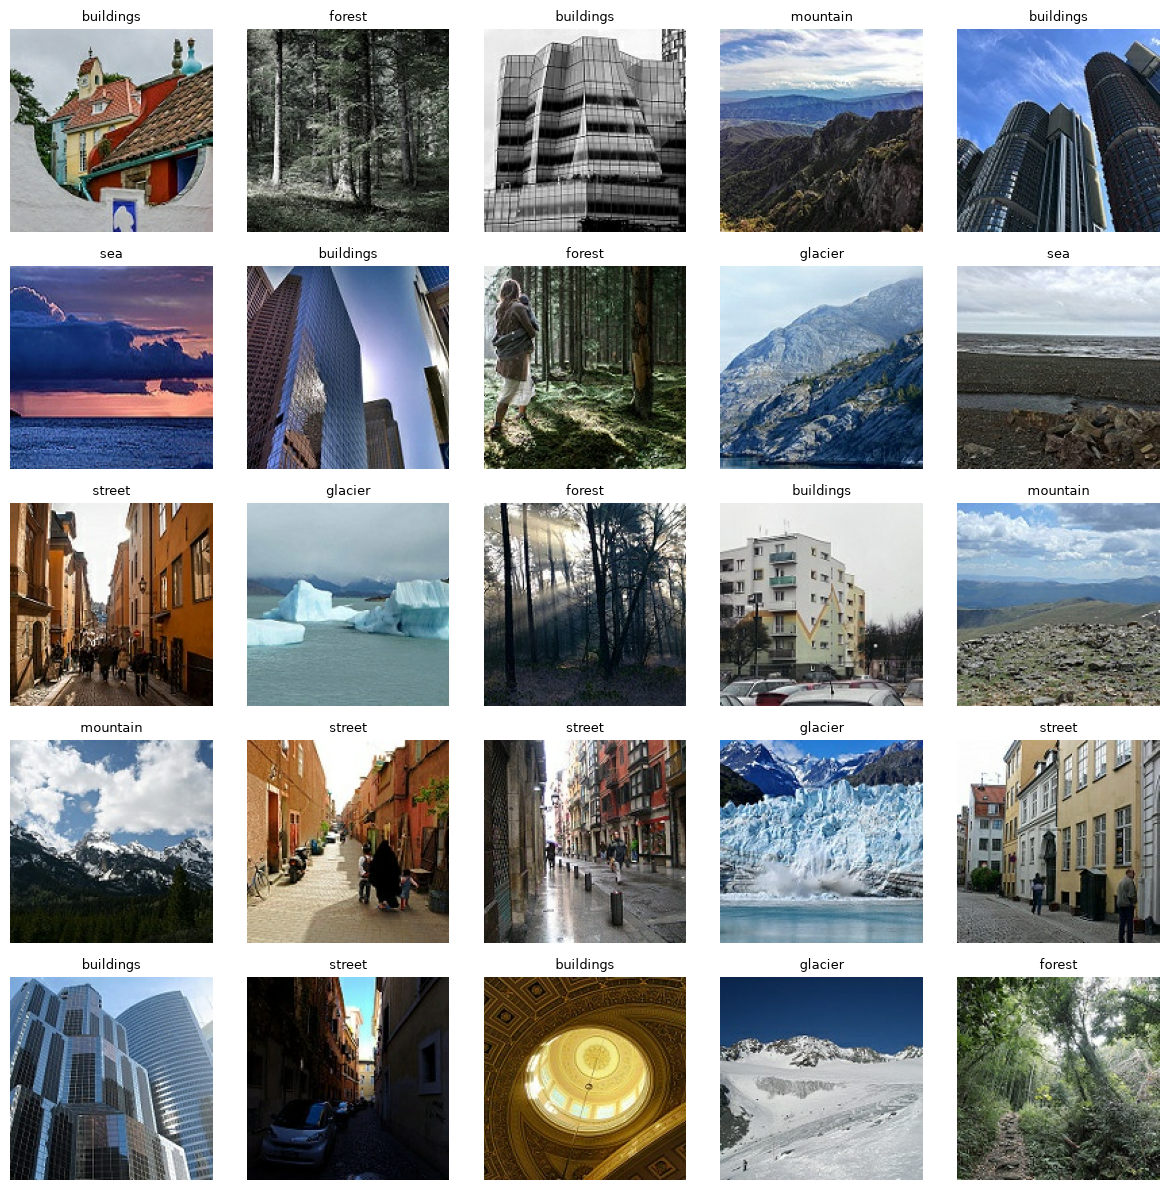

In [7]:
# Show 25 sample images

plt.figure(figsize=(12, 12))

images, labels = next(iter(train_ds))

for i in range(25):
    ax = plt.subplot(5, 5, i + 1)

    # Convert MobileNetV2 [-1, 1] values back to [0, 1] for display
    img = (images[i].numpy() + 1.0) / 2.0

    plt.imshow(img)
    plt.title(class_names[int(labels[i])], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()


### Learning Rate Schedulers

In [8]:
# Must be input as callback in train_and_test(....   , callbacks=[reduce_lr] )

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',    # Quantity to be monitored.
    factor=0.5,            # Factor by which the learning rate will be reduced.
                           # new_lr = lr * factor
    patience=3,            # Number of epochs with no improvement
                           # after which learning rate will be reduced.
    min_delta=1e-4,        # Threshold for measuring the new optimum,
                           # to only focus on significant changes.
    cooldown=0,            # Number of epochs to wait before resuming
                           # normal operation after lr has been reduced.
    min_lr=1e-7,           # Lower bound on the learning rate.
    verbose=1,             # 0: quiet, 1: update messages.
)

### Prelude: Baseline Model

`MobileNetV2` is a lightweight CNN pretrained on the ImageNet dataset. We will use it as a source of high-quality visual features rather than training a convolutional network from scratch.

See the **Appendix** for additional information about `MobileNetV2`.

The baseline model defined below uses `MobileNetV2` as a frozen **feature extractor**. With `include_top=False` and built-in **Global Average Pooling**, the backbone produces a 1280-dimensional feature vector for each image.

The images have already been processed using `mobilenet_v2.preprocess_input`, which scales the pixel values to the range expected by the pretrained MobileNetV2 weights.

> **NOTE:** The standard MobileNetV2 ImageNet weights are associated with 224×224 images. We use 150×150 images to reduce training time. This is valid because, with `include_top=False`, the convolutional backbone can operate on different input image sizes.
>
> Keras may therefore issue a warning such as:
>
> `UserWarning: input_shape is undefined or non-square, ...`
>
> You may safely ignore this warning for this assignment.


In [9]:
# ALWAYS construct a new instance to avoid sharing layers across models.

def make_base_model_pooled(trainable=False):
    base = mobilenet_v2.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=INPUT_SHAPE,
        pooling="avg",
    )
    base.trainable = trainable
    return base


base = make_base_model_pooled()

print("Some statistics on the model:")
print("Total Keras layers:", len(base.layers))

# Count unique inverted-residual blocks by their prefix 'block_<n>'
block_ids = sorted({
    int(layer.name.split("_")[1])
    for layer in base.layers
    if layer.name.startswith("block_")
})
print("Conv Block IDs:", block_ids, "(count:", len(block_ids), ")")

# Check whether the final Conv_1 stage exists
has_conv1 = any(
    layer.name.startswith("Conv_1")
    for layer in base.layers
)

print("Has Conv_1 stage:", has_conv1)
print("Model Output Shape:", base.output_shape)

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(


Some statistics on the model:
Total Keras layers: 155
Conv Block IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16] (count: 16 )
Has Conv_1 stage: True
Model Output Shape: (None, 1280)


In [10]:
# Ha, this is very long!

# base.summary()

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



Model Baseline

Epoch 1/500


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1790633920.569982   47309 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7755 - loss: 0.6081 

E0000 00:00:1790633927.514577   47309 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.7756 - loss: 0.6084

E0000 00:00:1790633932.803972   47312 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


88/88 ━━━━━━━━━━━━━━━━━━━━ 18s 121ms/step - accuracy: 0.7756 - loss: 0.6084 - val_accuracy: 0.8670 - val_loss: 0.3456
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8967 - loss: 0.2898 - val_accuracy: 0.8469 - val_loss: 0.3586
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9170 - loss: 0.2286 - val_accuracy: 0.8784 - val_loss: 0.3112
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9280 - loss: 0.1932 - val_accuracy: 0.8913 - val_loss: 0.3126
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9466 - loss: 0.1628 - val_accuracy: 0.8784 - val_loss: 0.3184
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9530 - loss: 0.1419 - val_accuracy: 0.8755 - val_loss: 0.3193
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9615 - loss: 0.1283 - val_accuracy: 0.8755 - val_loss: 0.3240
Epoch 8/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9651 - loss: 0.1164 - val_accuracy: 0.8898 - val

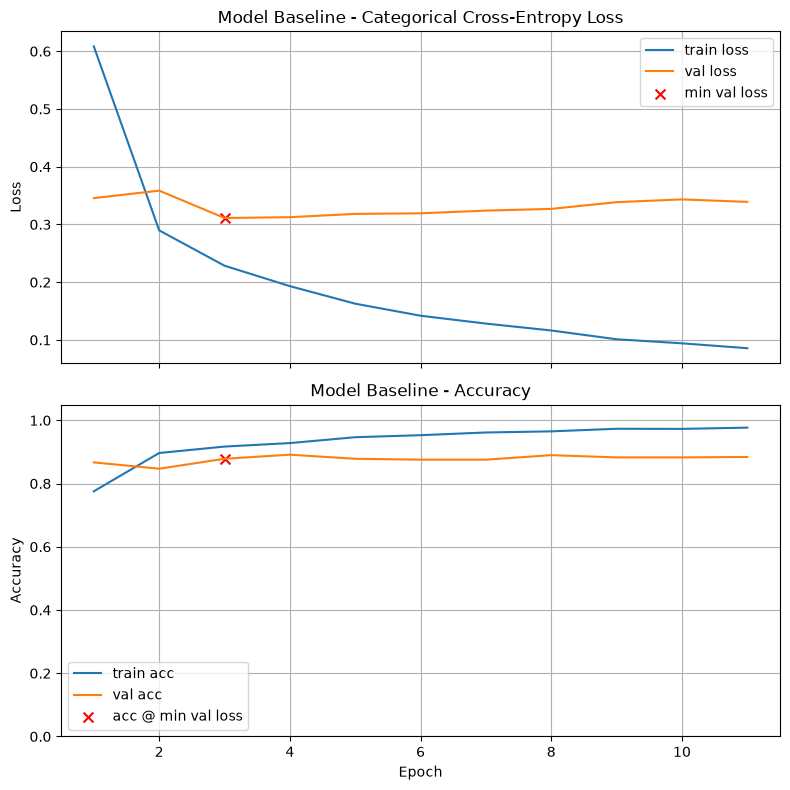

Final Training Loss:            0.0856
Final Training Accuracy:        0.9768
Final Validation Loss:          0.3391
Final Validation Accuracy:      0.8841
Minimum Validation Loss:        0.3112 (Epoch 3)
Validation Accuracy @ Min Loss: 0.8784


E0000 00:00:1790633946.626265   47311 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Test Loss: 0.2742
Test Accuracy: 0.9037

Validation-Test Gap (accuracy): 0.025346

Execution Time: 00:00:30


In [11]:
# Construct a fresh frozen MobileNetV2 backbone

base_model = make_base_model_pooled()

model_baseline = models.Sequential([
    base_model,
    Dense(num_classes, activation='softmax')  # use your Intel num_classes (6)
])

train_and_test(model_baseline, title="Model Baseline")

### Problem 1 — Frozen MobileNetV2 (Feature Extractor): Redesign the Head

**Goal.** Keep the MobileNetV2 backbone **frozen** and try to improve accuracy by modifying **only the classification head**.

**Setup.**

```python
base = make_base_model_pooled(
    trainable=False
)  # MobileNetV2(include_top=False, pooling="avg")
```

This backbone already applies **Global Average Pooling** and outputs a **1280-D feature vector** for each image.

Do **not** unfreeze any backbone layers, and do **not** add another pooling layer.

### To Do

1. **Ask an AI helper** (e.g., ChatGPT):

   *“What are some more complex classification heads that could improve this model on the Intel Image Classification Dataset, without unfreezing the MobileNetV2 backbone?”*

2. **Implement at least three different head designs.** These may be AI-suggested or inspired by techniques used in HW4.

3. **Experiment with hyperparameters** for the different designs, such as:

   * learning rate
   * `EarlyStopping` settings
   * Dropout and/or L2 regularization
   * `ReduceLROnPlateau` on or off

4. **Train and compare** the three head designs using a reduced value of `DATA_FRACTION`.

   Use these runs to compare architectures and training behavior and to narrow down a reasonable final configuration.

5. **Select one configuration**, set:

```python
DATA_FRACTION = 1.0
```

and rerun the notebook on the full dataset. Use this full-data run when answering the graded questions.

6. **Answer the graded questions.**

### Notes / Constraints

* With `pooling="avg"`, the backbone output has shape **(None, 1280)**, so **do not add `GlobalAveragePooling2D()`** to the head.
* `BatchNormalization` may be used within the classification head.
* Keep the entire MobileNetV2 backbone frozen for all experiments in this problem.
* Construct a **new backbone/model for each experiment** so that experiments do not inherit weights from previous runs.
* Small shifts in relative performance between reduced-data experiments and the full dataset are expected.



#### Design 1: Dense Layer (256 relu)

##### Baseline

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 1. Dense 256

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.8354 - loss: 0.4837 - val_accuracy: 0.8770 - val_loss: 0.3291
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9330 - loss: 0.1982 - val_accuracy: 0.8927 - val_loss: 0.3368
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9494 - loss: 0.1410 - val_accuracy: 0.8727 - val_loss: 0.3700
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9733 - loss: 0.0861 - val_accuracy: 0.8870 - val_loss: 0.3512
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9772 - loss: 0.0707 - val_accuracy: 0.8913 - val_loss: 0.3683
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9893 - loss: 0.0399 - val_accuracy: 0.8870 - val_loss: 0.3887
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9925 - loss: 0.0258 - val_accuracy: 0.8870 - val_loss: 0.4211
Epoch 8/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9975 - loss:

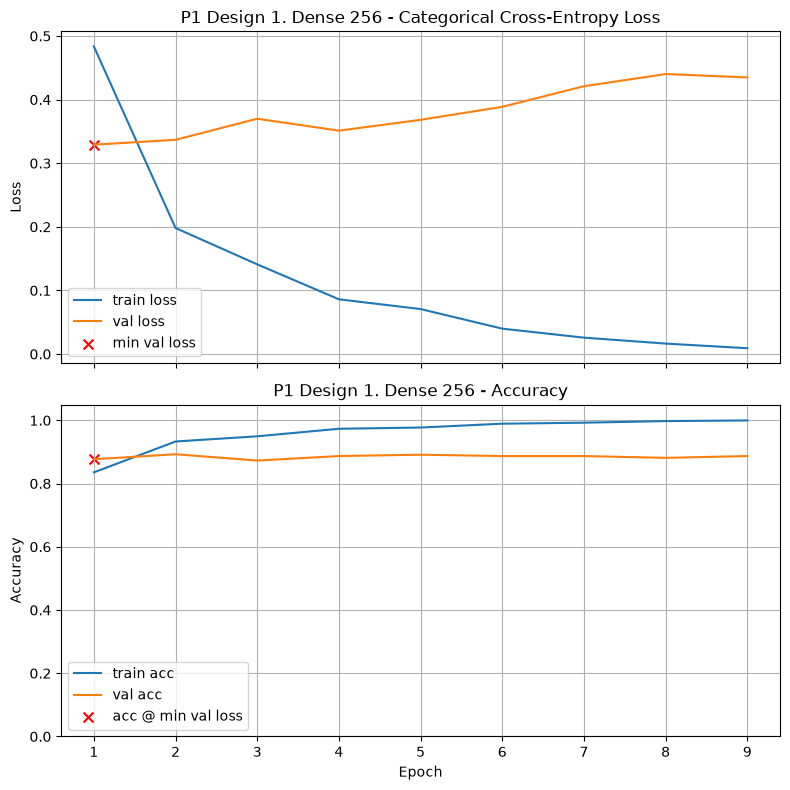

Final Training Loss:            0.0091
Final Training Accuracy:        0.9996
Final Validation Loss:          0.4349
Final Validation Accuracy:      0.8870
Minimum Validation Loss:        0.3291 (Epoch 1)
Validation Accuracy @ Min Loss: 0.8770

Test Loss: 0.2869
Test Accuracy: 0.9051

Validation-Test Gap (accuracy): 0.028113

Execution Time: 00:00:19


In [12]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d1_baseline = models.Sequential([
    base_model,
    Dense(256, activation='relu'),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d1_baseline, title="P1 Design 1. Dense 256")

##### Dropout 0.5

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 1. Dense 256 with Dropout

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - accuracy: 0.7652 - loss: 0.6750 - val_accuracy: 0.8712 - val_loss: 0.3295
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8853 - loss: 0.3273 - val_accuracy: 0.8870 - val_loss: 0.3161
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9024 - loss: 0.2651 - val_accuracy: 0.8870 - val_loss: 0.3324
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9209 - loss: 0.2164 - val_accuracy: 0.8698 - val_loss: 0.3628
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9284 - loss: 0.1847 - val_accuracy: 0.8856 - val_loss: 0.3231
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9366 - loss: 0.1640 - val_accuracy: 0.8712 - val_loss: 0.3769
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9473 - loss: 0.1476 - val_accuracy: 0.8770 - val_loss: 0.3552
Epoch 8/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0

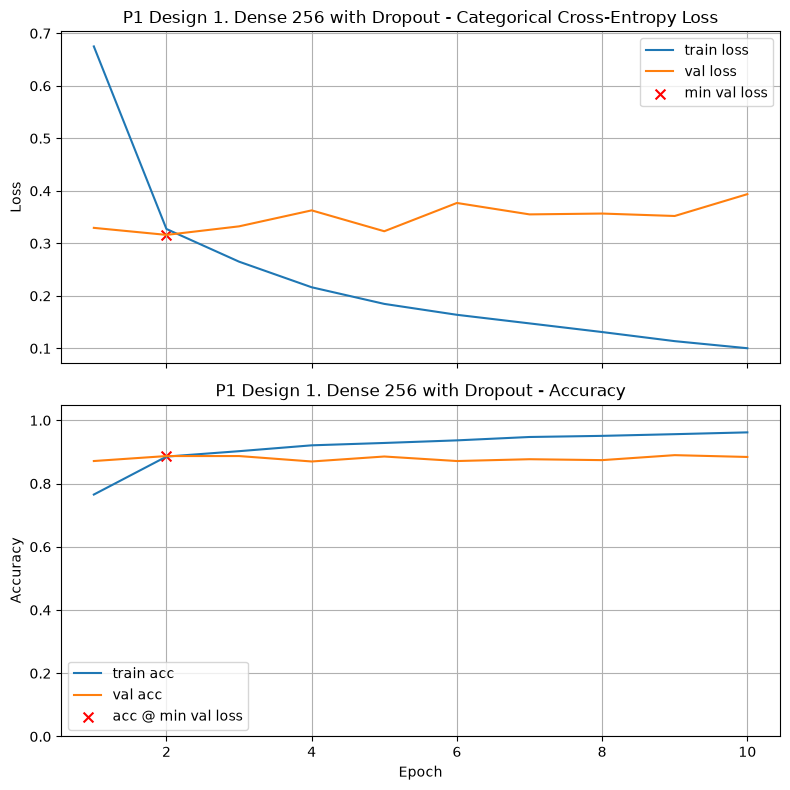

Final Training Loss:            0.1003
Final Training Accuracy:        0.9619
Final Validation Loss:          0.3937
Final Validation Accuracy:      0.8841
Minimum Validation Loss:        0.3161 (Epoch 2)
Validation Accuracy @ Min Loss: 0.8870

Test Loss: 0.2632
Test Accuracy: 0.9011

Validation-Test Gap (accuracy): 0.014088

Execution Time: 00:00:19


In [13]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d1_dropout = models.Sequential([
    base_model,
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d1_dropout, title="P1 Design 1. Dense 256 with Dropout")

##### Decreased lr 1e-4

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 1. Dense 256 with lr 1e-4

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - accuracy: 0.5354 - loss: 1.2900 - val_accuracy: 0.8412 - val_loss: 0.4883
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8066 - loss: 0.5533 - val_accuracy: 0.8798 - val_loss: 0.3744
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8415 - loss: 0.4364 - val_accuracy: 0.8941 - val_loss: 0.3300
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8721 - loss: 0.3679 - val_accuracy: 0.8870 - val_loss: 0.3161
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8856 - loss: 0.3191 - val_accuracy: 0.8898 - val_loss: 0.3019
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8924 - loss: 0.2989 - val_accuracy: 0.8956 - val_loss: 0.2973
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9020 - loss: 0.2768 - val_accuracy: 0.8941 - val_loss: 0.2937
Epoch 8/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.

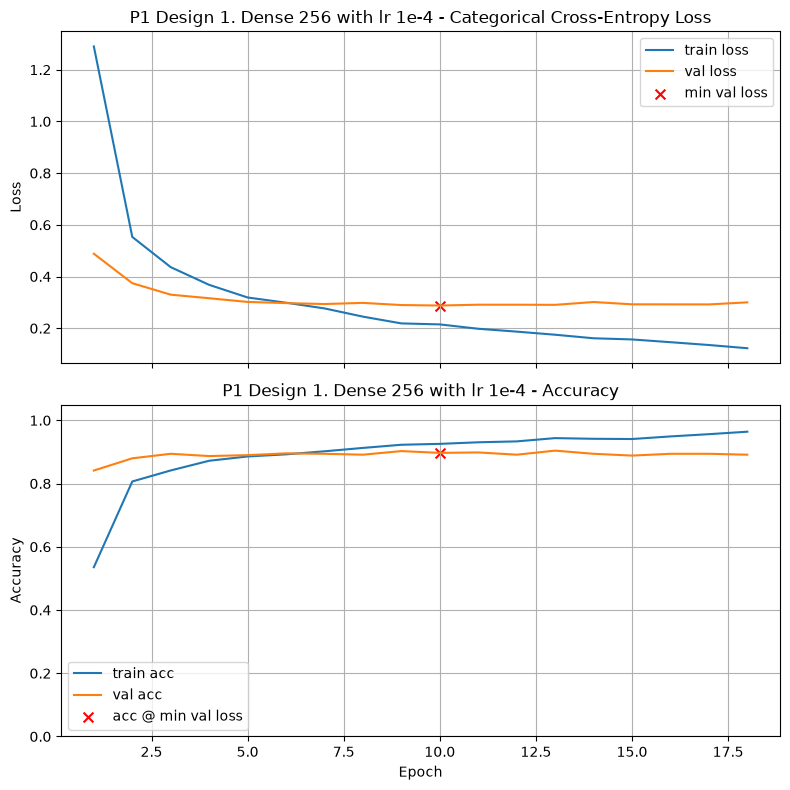

Final Training Loss:            0.1228
Final Training Accuracy:        0.9640
Final Validation Loss:          0.3002
Final Validation Accuracy:      0.8913
Minimum Validation Loss:        0.2879 (Epoch 10)
Validation Accuracy @ Min Loss: 0.8970

Test Loss: 0.2510
Test Accuracy: 0.9184

Validation-Test Gap (accuracy): 0.021453

Execution Time: 00:00:26


In [14]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d1_lr = models.Sequential([
    base_model,
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d1_lr, title="P1 Design 1. Dense 256 with lr 1e-4", lr_schedule=1e-4)

##### ReduceLROnPlateau

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 1. Dense 256 with ReduceLROnPlateau

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - accuracy: 0.8201 - loss: 0.4968 - val_accuracy: 0.8970 - val_loss: 0.3040 - learning_rate: 0.0010
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9216 - loss: 0.2133 - val_accuracy: 0.8755 - val_loss: 0.3594 - learning_rate: 0.0010
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9491 - loss: 0.1392 - val_accuracy: 0.8770 - val_loss: 0.3603 - learning_rate: 0.0010
Epoch 4/500
85/88 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9724 - loss: 0.0885
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9715 - loss: 0.0892 - val_accuracy: 0.8884 - val_loss: 0.3303 - learning_rate: 0.0010
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9865 - loss: 0.0479 - val_accuracy: 0.8941 - val_loss: 0.3359 - learning_rate: 5.0000e-04
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 

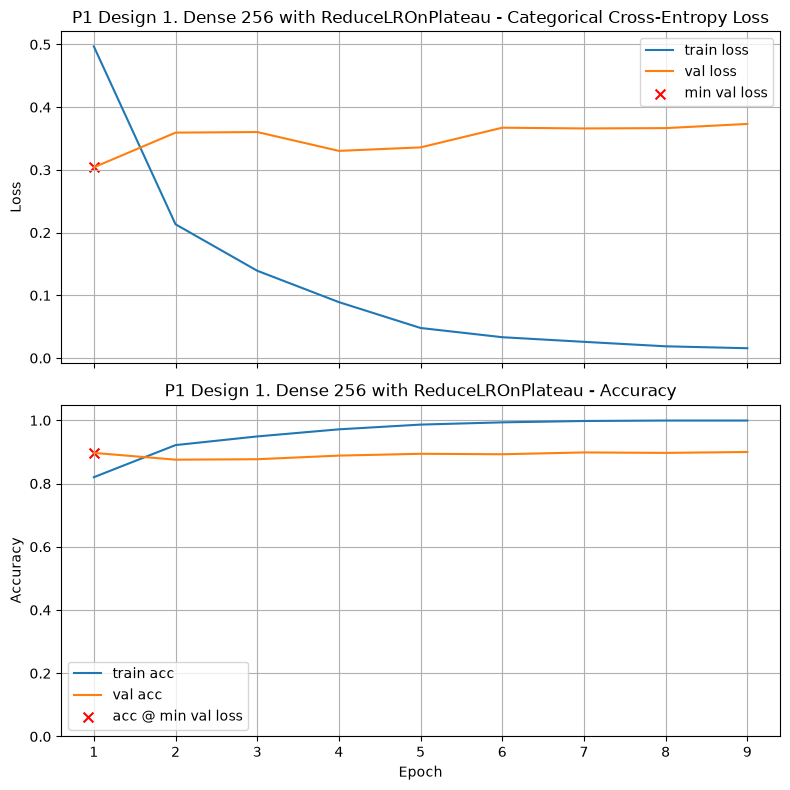

Final Training Loss:            0.0157
Final Training Accuracy:        0.9993
Final Validation Loss:          0.3732
Final Validation Accuracy:      0.8999
Minimum Validation Loss:        0.3040 (Epoch 1)
Validation Accuracy @ Min Loss: 0.8970

Test Loss: 0.2736
Test Accuracy: 0.8997

Validation-Test Gap (accuracy): 0.002737

Execution Time: 00:00:18


In [15]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d1_reduce_lr = models.Sequential([
    base_model,
    Dense(256, activation='relu'),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d1_reduce_lr, title="P1 Design 1. Dense 256 with ReduceLROnPlateau", callbacks=[reduce_lr])

##### Combination

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 1. Dense 256 with Dropout and ReduceLROnPlateau

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - accuracy: 0.7752 - loss: 0.6666 - val_accuracy: 0.8784 - val_loss: 0.3313 - learning_rate: 0.0010
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8960 - loss: 0.3003 - val_accuracy: 0.8856 - val_loss: 0.3179 - learning_rate: 0.0010
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9059 - loss: 0.2629 - val_accuracy: 0.8841 - val_loss: 0.3159 - learning_rate: 0.0010
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9188 - loss: 0.2246 - val_accuracy: 0.8941 - val_loss: 0.2917 - learning_rate: 0.0010
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9348 - loss: 0.1759 - val_accuracy: 0.8870 - val_loss: 0.3229 - learning_rate: 0.0010
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9405 - loss: 0.1572 - val_accuracy: 0.8870 - val_loss: 0.3279 - learning_rate: 0.0010
Epoch 7/500
85/88 ━━━━━━━━━

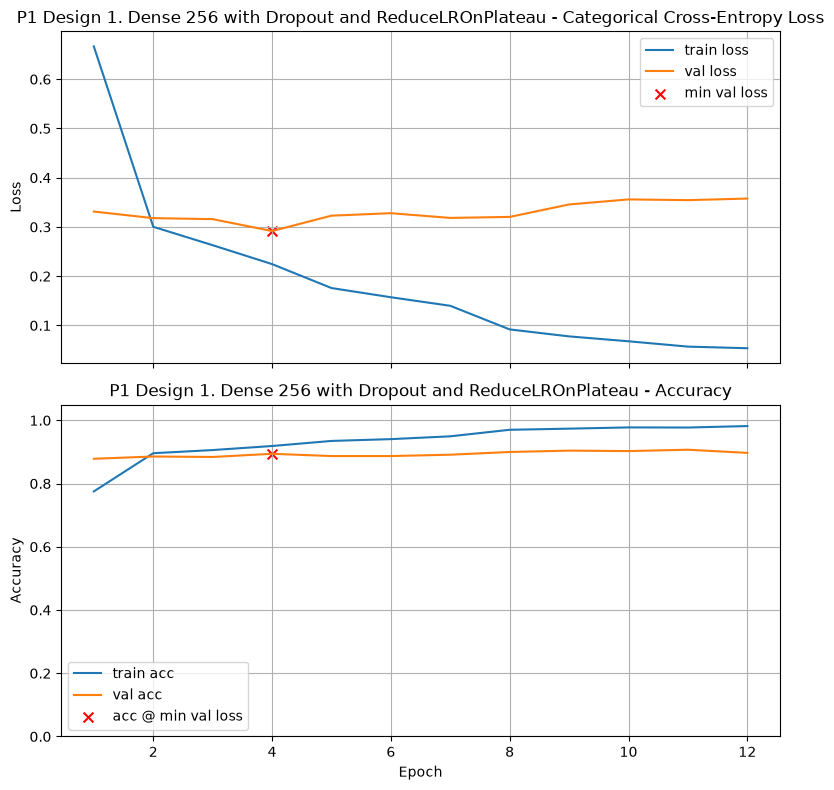

Final Training Loss:            0.0537
Final Training Accuracy:        0.9818
Final Validation Loss:          0.3577
Final Validation Accuracy:      0.8970
Minimum Validation Loss:        0.2917 (Epoch 4)
Validation Accuracy @ Min Loss: 0.8941

Test Loss: 0.2636
Test Accuracy: 0.8971

Validation-Test Gap (accuracy): 0.002924

Execution Time: 00:00:21


In [16]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d1_reduce_final = models.Sequential([
    base_model,
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d1_reduce_final, title="P1 Design 1. Dense 256 with Dropout and ReduceLROnPlateau", callbacks=[reduce_lr])

#### Design 2: Dense -> Dropout -> Dense -> Dropout

##### Baseline

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 2. Dense-Dropout-Dense-Dropout

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 88ms/step - accuracy: 0.7610 - loss: 0.6815 - val_accuracy: 0.8784 - val_loss: 0.3306
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8618 - loss: 0.3838 - val_accuracy: 0.8870 - val_loss: 0.2916
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8785 - loss: 0.3328 - val_accuracy: 0.8941 - val_loss: 0.3134
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9020 - loss: 0.2682 - val_accuracy: 0.9056 - val_loss: 0.2928
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9088 - loss: 0.2341 - val_accuracy: 0.8970 - val_loss: 0.3087
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9252 - loss: 0.2154 - val_accuracy: 0.9013 - val_loss: 0.2980
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9401 - loss: 0.1781 - val_accuracy: 0.8870 - val_loss: 0.3203
Epoch 8/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accura

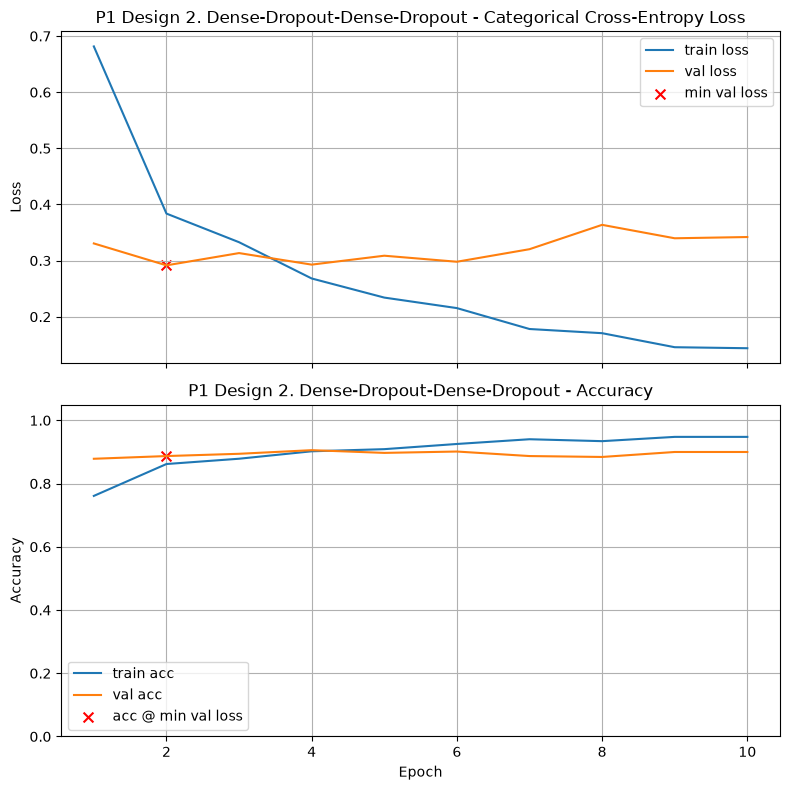

Final Training Loss:            0.1439
Final Training Accuracy:        0.9476
Final Validation Loss:          0.3420
Final Validation Accuracy:      0.8999
Minimum Validation Loss:        0.2916 (Epoch 2)
Validation Accuracy @ Min Loss: 0.8870

Test Loss: 0.2681
Test Accuracy: 0.9011

Validation-Test Gap (accuracy): 0.014088

Execution Time: 00:00:23


In [17]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d2_baseline = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d2_baseline, title="P1 Design 2. Dense-Dropout-Dense-Dropout")

##### Decreased lr 1e-4

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 2. Dense-Dropout-Dense-Dropout lr 1e-4

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.5226 - loss: 1.2572 - val_accuracy: 0.8398 - val_loss: 0.5267
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8016 - loss: 0.5790 - val_accuracy: 0.8627 - val_loss: 0.3862
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8418 - loss: 0.4483 - val_accuracy: 0.8770 - val_loss: 0.3331
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8636 - loss: 0.3883 - val_accuracy: 0.8827 - val_loss: 0.3195
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8764 - loss: 0.3413 - val_accuracy: 0.8913 - val_loss: 0.3183
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8864 - loss: 0.3181 - val_accuracy: 0.8884 - val_loss: 0.3162
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8928 - loss: 0.2830 - val_accuracy: 0.8898 - val_loss: 0.3085
Epoch 8/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step 

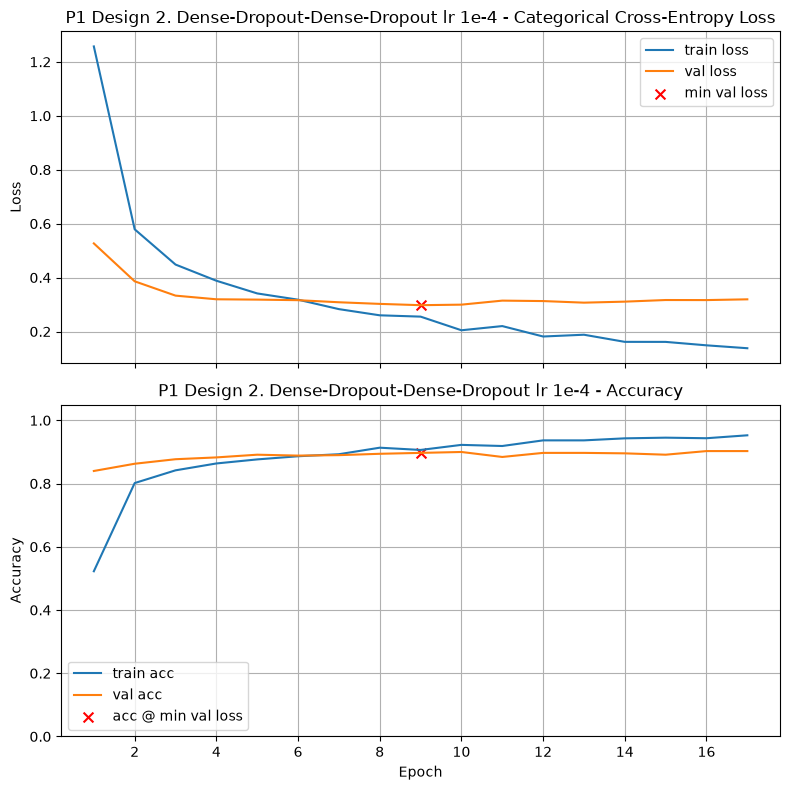

Final Training Loss:            0.1381
Final Training Accuracy:        0.9526
Final Validation Loss:          0.3194
Final Validation Accuracy:      0.9027
Minimum Validation Loss:        0.2976 (Epoch 9)
Validation Accuracy @ Min Loss: 0.8970

Test Loss: 0.2610
Test Accuracy: 0.9011

Validation-Test Gap (accuracy): 0.004074

Execution Time: 00:00:27


In [18]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d2_lr_1e4 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d2_lr_1e4, title="P1 Design 2. Dense-Dropout-Dense-Dropout lr 1e-4", lr_schedule=1e-4)

##### ReduceLROnPlateau

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 2. Dense-Dropout-Dense-Dropout ReuceLROnPlateau

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.7542 - loss: 0.7109 - val_accuracy: 0.8383 - val_loss: 0.4172 - learning_rate: 0.0010
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8639 - loss: 0.3779 - val_accuracy: 0.8712 - val_loss: 0.3489 - learning_rate: 0.0010
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8881 - loss: 0.3124 - val_accuracy: 0.8856 - val_loss: 0.3089 - learning_rate: 0.0010
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9027 - loss: 0.2683 - val_accuracy: 0.8941 - val_loss: 0.3067 - learning_rate: 0.0010
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9173 - loss: 0.2404 - val_accuracy: 0.8913 - val_loss: 0.3080 - learning_rate: 0.0010
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9184 - loss: 0.2240 - val_accuracy: 0.8941 - val_loss: 0.3244 - learning_rate: 0.0010
Epoch 7/500
85/88 ━━━━━━━━━

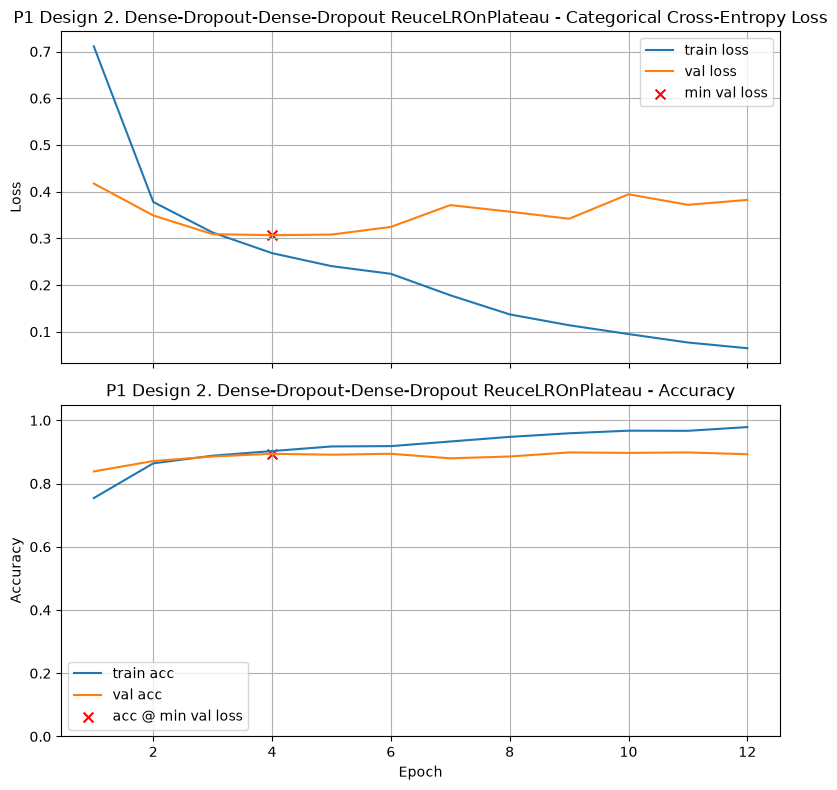

Final Training Loss:            0.0646
Final Training Accuracy:        0.9786
Final Validation Loss:          0.3822
Final Validation Accuracy:      0.8927
Minimum Validation Loss:        0.3067 (Epoch 4)
Validation Accuracy @ Min Loss: 0.8941

Test Loss: 0.2681
Test Accuracy: 0.8930

Validation-Test Gap (accuracy): 0.001086

Execution Time: 00:00:22


In [19]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d2_reduce_lr = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d2_reduce_lr, title="P1 Design 2. Dense-Dropout-Dense-Dropout ReuceLROnPlateau", callbacks=[reduce_lr])

#### Design 3: Dense-Dropout-Dense-Dropout with Regularization and Batch Normalization

##### Baseline

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 13s 86ms/step - accuracy: 0.7930 - loss: 0.7182 - val_accuracy: 0.8784 - val_loss: 0.4669
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8853 - loss: 0.4347 - val_accuracy: 0.8856 - val_loss: 0.4596
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9102 - loss: 0.3752 - val_accuracy: 0.8798 - val_loss: 0.5094
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9202 - loss: 0.3279 - val_accuracy: 0.8841 - val_loss: 0.4828
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9252 - loss: 0.3113 - val_accuracy: 0.8741 - val_loss: 0.5077
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9384 - loss: 0.2842 - val_accuracy: 0.8827 - val_loss: 0.4965
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9373 - loss: 0.2751 - val_accuracy: 0.8884 - val_loss: 0.4809
Epoch 8/500
88/88 ━━━━━━━━━━━━━━━━

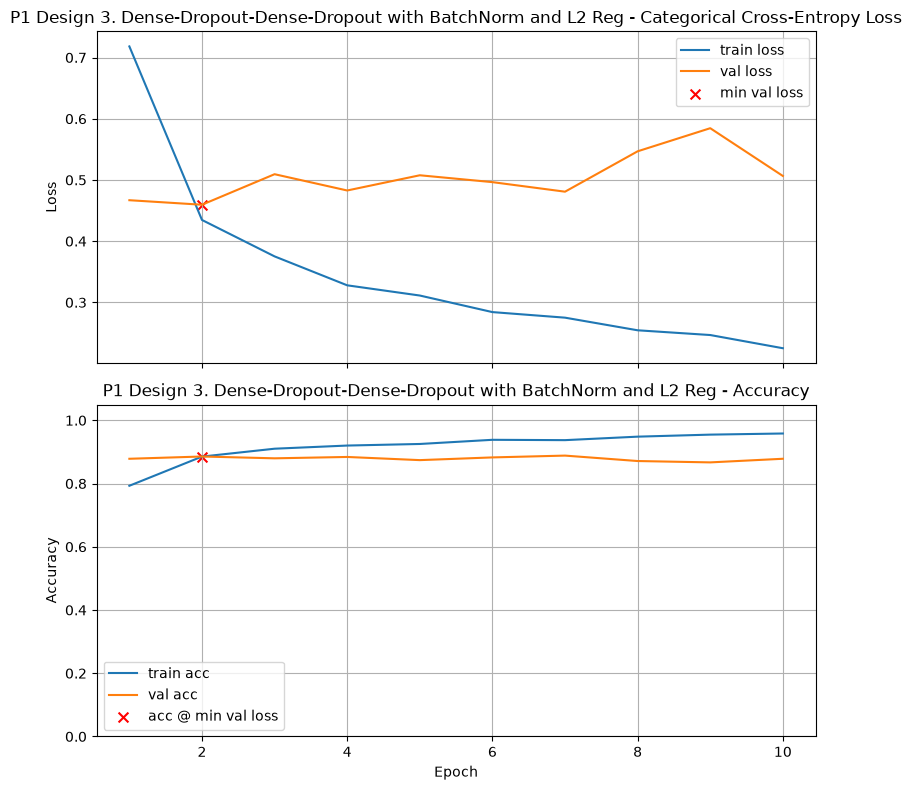

Final Training Loss:            0.2252
Final Training Accuracy:        0.9583
Final Validation Loss:          0.5066
Final Validation Accuracy:      0.8784
Minimum Validation Loss:        0.4596 (Epoch 2)
Validation Accuracy @ Min Loss: 0.8856

Test Loss: 0.4094
Test Accuracy: 0.8971

Validation-Test Gap (accuracy): 0.011508

Execution Time: 00:00:23


In [20]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d3_baseline = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d3_baseline, title="P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg")

##### Decreased regularization 1e-3

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg 1e-3

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - accuracy: 0.7969 - loss: 1.6775 - val_accuracy: 0.8784 - val_loss: 1.4281
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8878 - loss: 1.3525 - val_accuracy: 0.8870 - val_loss: 1.3453
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9081 - loss: 1.2428 - val_accuracy: 0.8655 - val_loss: 1.3231
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9156 - loss: 1.1429 - val_accuracy: 0.8755 - val_loss: 1.2524
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9305 - loss: 1.0512 - val_accuracy: 0.8784 - val_loss: 1.2489
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9284 - loss: 0.9773 - val_accuracy: 0.8870 - val_loss: 1.1426
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9323 - loss: 0.9180 - val_accuracy: 0.8655 - val_loss: 1.2012
Epoch 8/500
88/88 ━━━━━━━━━━━

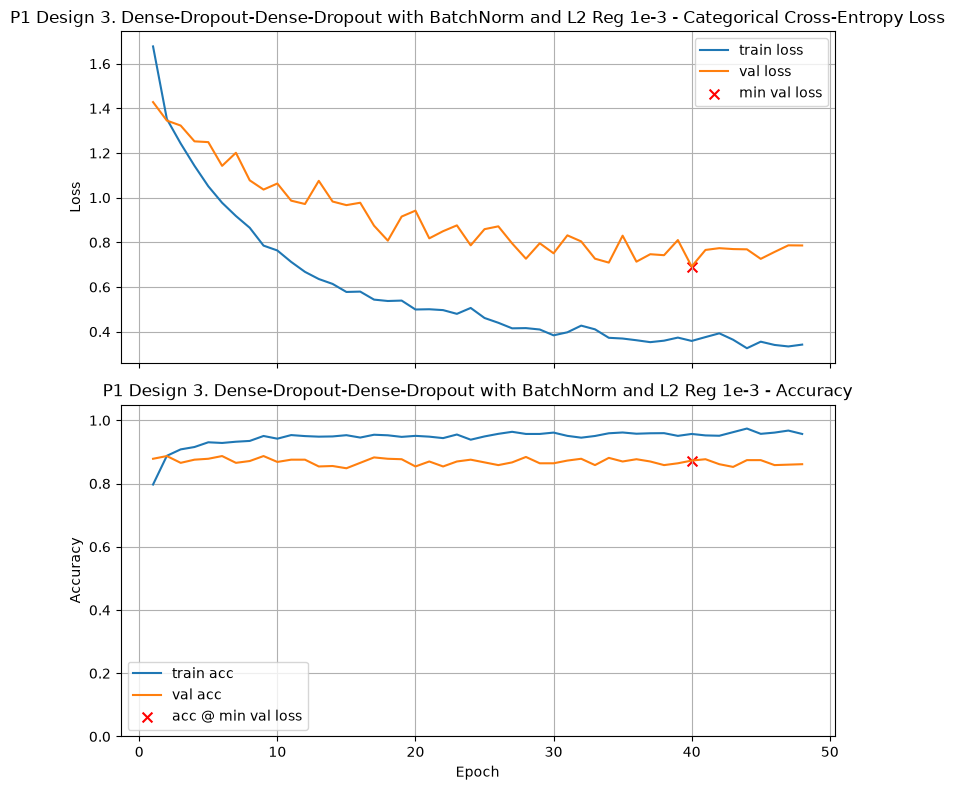

Final Training Loss:            0.3421
Final Training Accuracy:        0.9569
Final Validation Loss:          0.7860
Final Validation Accuracy:      0.8612
Minimum Validation Loss:        0.6917 (Epoch 40)
Validation Accuracy @ Min Loss: 0.8727

Test Loss: 0.5923
Test Accuracy: 0.8877

Validation-Test Gap (accuracy): 0.015025

Execution Time: 00:00:59


In [21]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d3_decreased_reg = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d3_decreased_reg, title="P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg 1e-3")

##### ReduceLROnPlateau

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg and ReduceLR

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 12s 85ms/step - accuracy: 0.8033 - loss: 0.7216 - val_accuracy: 0.8484 - val_loss: 0.5518 - learning_rate: 0.0010
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8892 - loss: 0.4268 - val_accuracy: 0.8655 - val_loss: 0.5331 - learning_rate: 0.0010
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9045 - loss: 0.3798 - val_accuracy: 0.8841 - val_loss: 0.4876 - learning_rate: 0.0010
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9241 - loss: 0.3262 - val_accuracy: 0.8784 - val_loss: 0.4712 - learning_rate: 0.0010
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9291 - loss: 0.3011 - val_accuracy: 0.8741 - val_loss: 0.4956 - learning_rate: 0.0010
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9369 - loss: 0.2815 - val_accuracy: 0.8784 - val_loss: 0.5152 - learning_rate: 0.0010
Epoch

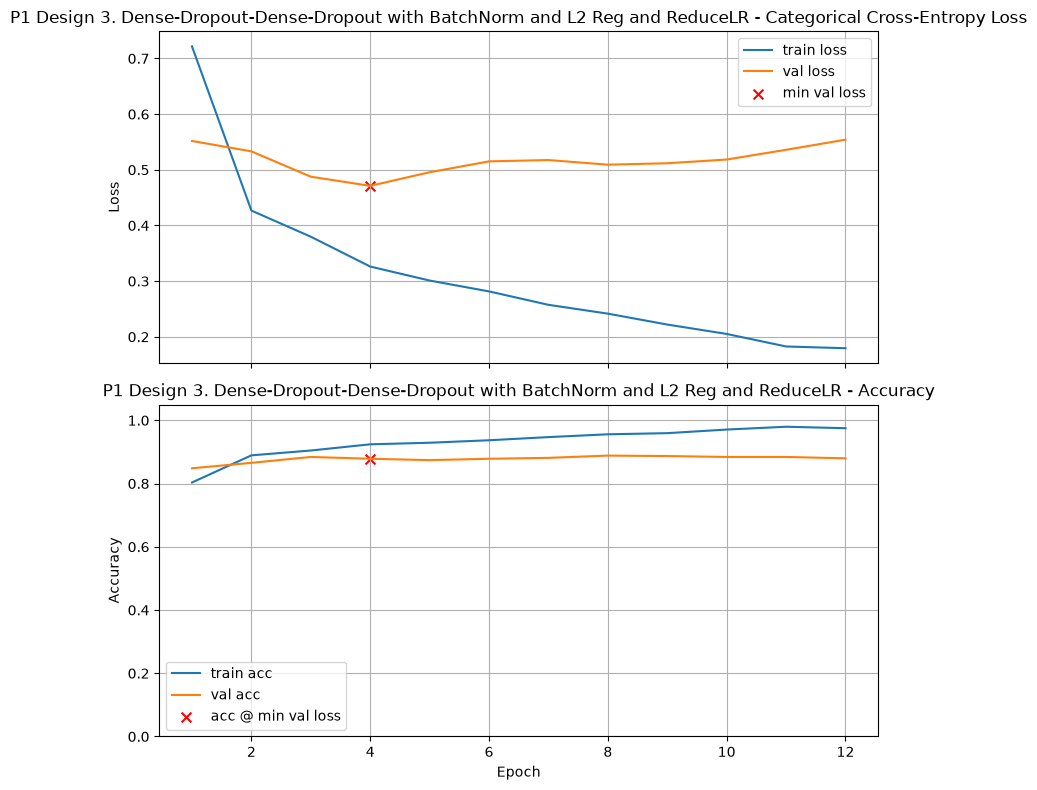

Final Training Loss:            0.1795
Final Training Accuracy:        0.9751
Final Validation Loss:          0.5541
Final Validation Accuracy:      0.8798
Minimum Validation Loss:        0.4712 (Epoch 4)
Validation Accuracy @ Min Loss: 0.8784

Test Loss: 0.4261
Test Accuracy: 0.9078

Validation-Test Gap (accuracy): 0.029356

Execution Time: 00:00:24


In [22]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d3_reduce_lr = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d3_reduce_lr, title="P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg and ReduceLR", callbacks=[reduce_lr])

# Graded Questions

The reflection question is worth 5 points, and the validation accuracy question is worth 15 points. 

**Reflection Question:**

Which head architecture worked best for you, and what does that suggest about the role of head design and hyperparameters when the backbone is frozen?

**Instructions:**

- Write a single paragraph (3–5 sentences).
- Identify the head architecture and experiment that performed best.
- Briefly compare it with the other experiments, referring to specific design choices (e.g., dense layers, dropout) and hyperparameters (e.g., learning rate, ReduceLROnPlateau).
- Explain which of these differences you think were most important, based on your observed training and validation results.
- Conclude with what your experiments suggest about designing classification heads when the backbone is frozen.


In [23]:
print_results()

P1 Design 1. Dense 256 with lr 1e-4     	0.8970	10
P1 Design 1. Dense 256 with ReduceLROnPlateau	0.8970	1
P1 Design 2. Dense-Dropout-Dense-Dropout lr 1e-4	0.8970	9
P1 Design 1. Dense 256 with Dropout and ReduceLROnPlateau	0.8941	4
P1 Design 2. Dense-Dropout-Dense-Dropout ReuceLROnPlateau	0.8941	4
P1 Design 1. Dense 256 with Dropout     	0.8870	2
P1 Design 2. Dense-Dropout-Dense-Dropout	0.8870	2
P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg	0.8856	2
Model Baseline                          	0.8784	3
P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg and ReduceLR	0.8784	4
P1 Design 1. Dense 256                  	0.8770	1
P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg 1e-3	0.8727	40


I experimented with three architectures-the first architecture used a simple model using a single Dense 256 layer and I tested out hyperparameters such as learning rate, ReduceLROnPlateau, and Dropout; the second archtiecture consists of 512 Dense Layer, Dropout, 256 Dense Layer, Dropout; the third architecture consists of 512 Dense Layer (L2 Regularized), BatchNormalization, Dropout, 256 Dense Layer (L2 Regularized), BatchNormalization, Dropout.

The first and second architectures performed the best, each consistently in the 0.894 - 0.897 validation accuracy range, providing a modest lift from the baseline model which had 0.8784 validation accuracy. Our best model received 0.8970 validation accuracy at the optimal loss using a Dense 256 layer with learning rate 1e-4. This model was tied with the Dense 256 using ReduceLROnPlateau and the Dense-Dropout-Dense-Dropout with learning rate 1e-4.

Based on these results, we can see that the learning rate had the most significant impact on the validation accuracy. We can conclude that there was no benefit in more complex head architectures across my experiments over a simpler model as long as the optimal learning rate or reduce learning rate on plateau was used. This shows that with a strong frozen backbone, a simpler head architecture can be used to modestly boost model performance on a specific domain. To further research, more granular hyperparamter tuning could be performed on the complex architectures to test more optimal parameter selections.

**Validation Accuracy here (15 pts):**

In [36]:
# Set a1 to the validation accuracy found by your best model for this problem. 

a1 = 0.8970             # Replace 0.0 with your answer

In [37]:
# Graded Answer
# DO NOT change this cell in any way and do not make any other assignments to variable a1a in this problem         

print(f'a1 = {a1:.4f}') 


a1 = 0.8970


## Problem Two — Training MobileNetV2 with the Backbone Unfrozen

**Goal.** Use the architecture of one of your best heads from Problem 1, but now make the MobileNetV2 backbone trainable so that the entire network can adapt to the Intel Image dataset.

**Setup.** Build a new MobileNetV2 backbone with `trainable=True`. It already applies Global Average Pooling and outputs a 1280-D vector, so do not add another pooling layer.

```python
base = make_base_model_pooled(
    trainable=True
)  # MobileNetV2(include_top=False, pooling="avg")
```

### To Do

1. **Design at least three experiments** with the MobileNetV2 backbone fully unfrozen. Use the architecture of one of your best heads from Problem 1 and vary one or more of the following:

   * **Learning rate**
   * **EarlyStopping** parameters
   * **Regularization:** Dropout and/or L2
   * **ReduceLROnPlateau:** on vs. off

2. **Run and compare** the three experiments using a reduced value of `DATA_FRACTION`, focusing on:

   * training stability,
   * convergence behavior,
   * and validation performance trends.

   Use these runs to **narrow down reasonable configurations**, not to identify a single “optimal” setting.

3. **Select one configuration**, set `DATA_FRACTION = 1.0`, rerun the notebook to train on the full dataset, and use this run when answering the graded questions.

### Notes

* Training a pretrained backbone generally requires a **much smaller learning rate** than training only a new classification head. Values such as \(1\times10^{-5}\) to \(3\times10^{-5}\) are reasonable starting points.
* Small changes in relative performance between experiments using a reduced dataset and the full dataset are expected.
* Each experiment should construct a **new model** so that experiments do not inherit weights from previous runs.



#### Experiment 1: Learning Rate Adjustments 

##### Baseline

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P2 Experiment 1 - LR Baseline

Epoch 1/500


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 49s 252ms/step - accuracy: 0.7481 - loss: 0.7389 - val_accuracy: 0.6738 - val_loss: 4.6291 - learning_rate: 0.0010
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.8500 - loss: 0.4782 - val_accuracy: 0.5079 - val_loss: 7.6593 - learning_rate: 0.0010
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.8682 - loss: 0.4686 - val_accuracy: 0.5379 - val_loss: 3.4289 - learning_rate: 0.0010
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.8928 - loss: 0.3686 - val_accuracy: 0.3019 - val_loss: 11.4952 - learning_rate: 0.0010
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9059 - loss: 0.3299 - val_accuracy: 0.5279 - val_loss: 3.0226 - learning_rate: 0.0010
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9145 - loss: 0.2907 - val_accuracy: 0.5751 - val_loss: 2.1569 - learning_rate: 0.0010
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9259 - loss: 0.2600 - val_accur

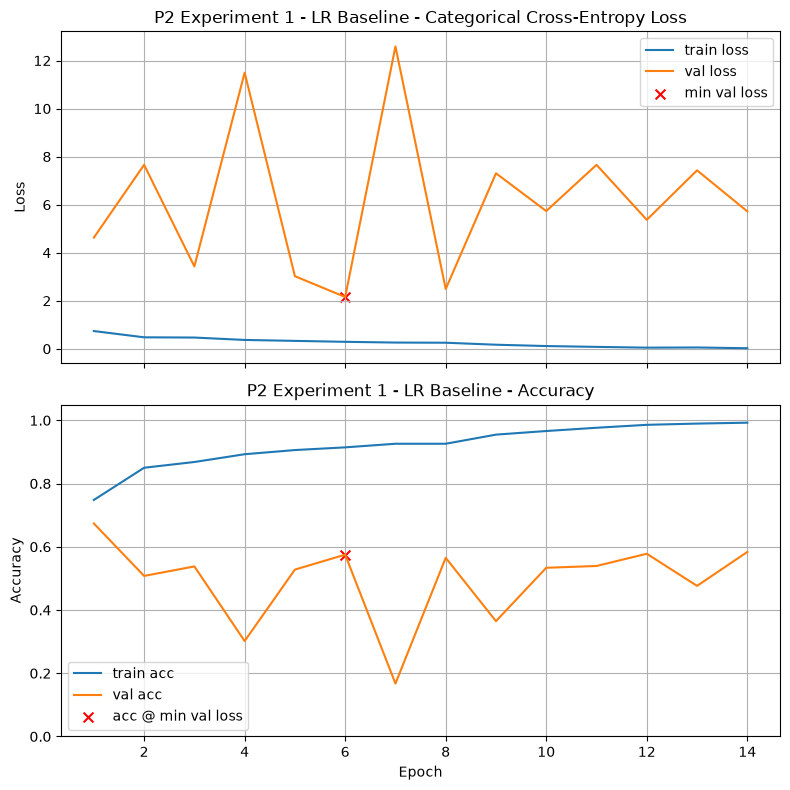

Final Training Loss:            0.0239
Final Training Accuracy:        0.9925
Final Validation Loss:          5.7221
Final Validation Accuracy:      0.5837
Minimum Validation Loss:        2.1569 (Epoch 6)
Validation Accuracy @ Min Loss: 0.5751

Test Loss: 2.4025
Test Accuracy: 0.5441

Validation-Test Gap (accuracy): 0.030990

Execution Time: 00:01:27


In [38]:
base_model = make_base_model_pooled(trainable=True)

model_p2_d1_lr_baseline = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p2_d1_lr_baseline, title="P2 Experiment 1 - LR Baseline", callbacks=[reduce_lr])

##### Decrease LR 1e-5

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P2 Experiment 1 - LR 1e-5

Epoch 1/500


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 36s 187ms/step - accuracy: 0.2259 - loss: 1.9930 - val_accuracy: 0.3433 - val_loss: 1.6034 - learning_rate: 1.0000e-05
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.3352 - loss: 1.6580 - val_accuracy: 0.5894 - val_loss: 1.2642 - learning_rate: 1.0000e-05
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.4464 - loss: 1.4275 - val_accuracy: 0.7268 - val_loss: 0.9891 - learning_rate: 1.0000e-05
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.5540 - loss: 1.1884 - val_accuracy: 0.7725 - val_loss: 0.7644 - learning_rate: 1.0000e-05
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.6427 - loss: 0.9970 - val_accuracy: 0.8097 - val_loss: 0.6139 - learning_rate: 1.0000e-05
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6929 - loss: 0.8729 - val_accuracy: 0.8255 - val_loss: 0.5184 - learning_rate: 1.0000e-05
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.7467 - l

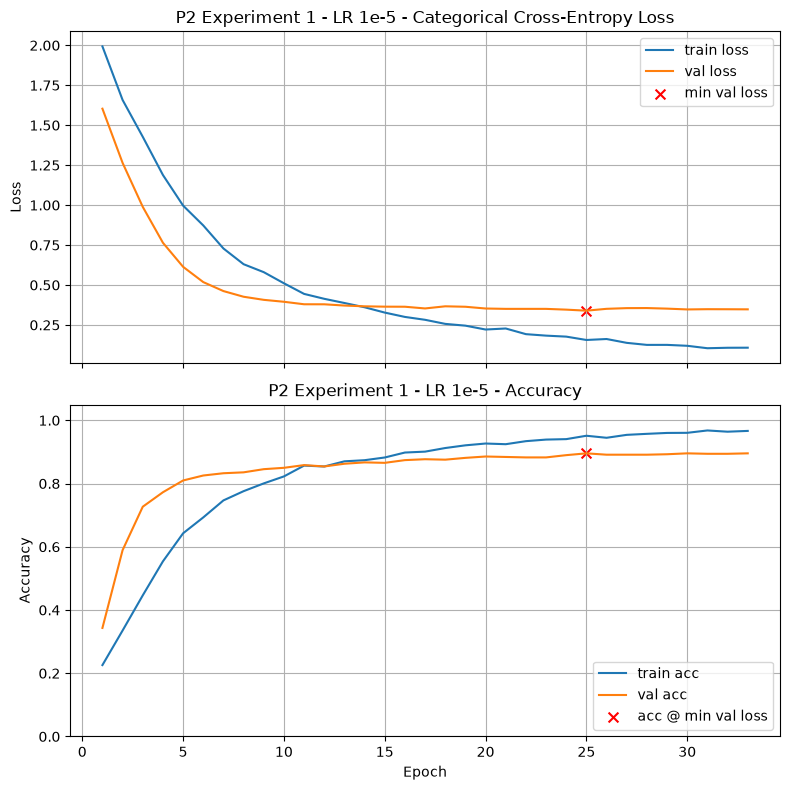

Final Training Loss:            0.1079
Final Training Accuracy:        0.9665
Final Validation Loss:          0.3478
Final Validation Accuracy:      0.8956
Minimum Validation Loss:        0.3395 (Epoch 25)
Validation Accuracy @ Min Loss: 0.8956

Test Loss: 0.2921
Test Accuracy: 0.9104

Validation-Test Gap (accuracy): 0.014863

Execution Time: 00:02:06


In [41]:
base_model = make_base_model_pooled(trainable=True)

model_p2_d1_lr_1e5 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p2_d1_lr_1e5, title="P2 Experiment 1 - LR 1e-5", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 2: Adjust Regularization

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P2 Experiment 1 - LR 1e-5 with L2Reg

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 37s 183ms/step - accuracy: 0.2148 - loss: 2.0965 - val_accuracy: 0.4320 - val_loss: 1.6176 - learning_rate: 1.0000e-05
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.3377 - loss: 1.7669 - val_accuracy: 0.6252 - val_loss: 1.3126 - learning_rate: 1.0000e-05
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.4685 - loss: 1.5080 - val_accuracy: 0.7396 - val_loss: 1.0632 - learning_rate: 1.0000e-05
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.5572 - loss: 1.2925 - val_accuracy: 0.7911 - val_loss: 0.8718 - learning_rate: 1.0000e-05
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6480 - loss: 1.1000 - val_accuracy: 0.8197 - val_loss: 0.7347 - learning_rate: 1.0000e-05
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.6947 - loss: 0.9620 - val_accuracy: 0.8355 - val_loss: 0.6415 - learning_rate: 1.0000e-05
Epoch 7/500
88/88 ━━━━━

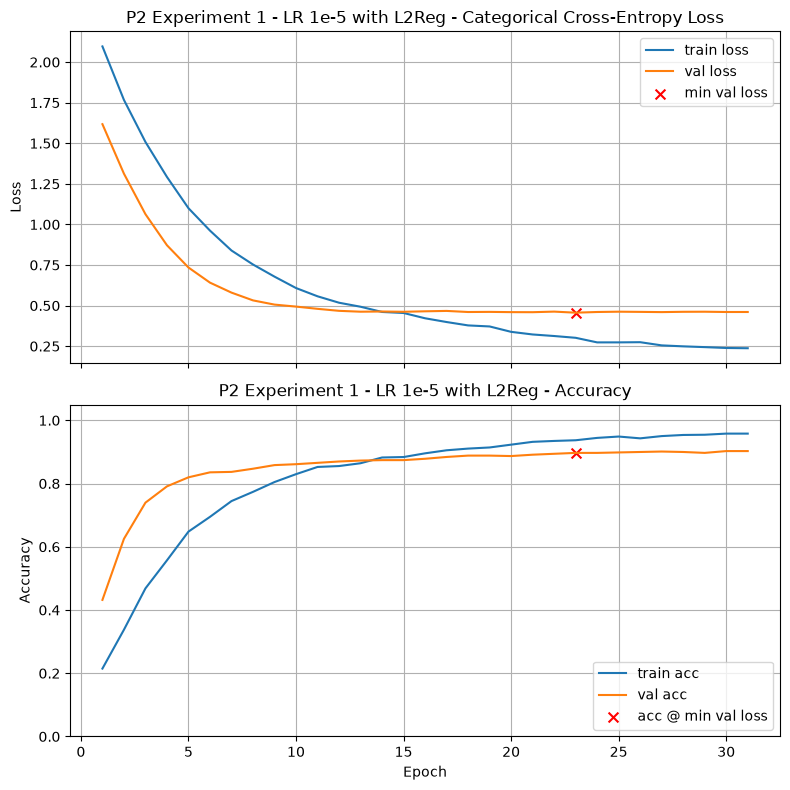

Final Training Loss:            0.2375
Final Training Accuracy:        0.9580
Final Validation Loss:          0.4607
Final Validation Accuracy:      0.9027
Minimum Validation Loss:        0.4564 (Epoch 23)
Validation Accuracy @ Min Loss: 0.8970

Test Loss: 0.3944
Test Accuracy: 0.9064

Validation-Test Gap (accuracy): 0.009421

Execution Time: 00:02:01


In [46]:
base_model = make_base_model_pooled(trainable=True)

model_p2_d2_l2 = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p2_d2_l2, title="P2 Experiment 1 - LR 1e-5 with L2Reg", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 3: Disable ReduceLROnPlateau

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P2 Experiment 1 - LR 1e-5, L2Reg, and no ReduceLROnPlateau

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 39s 195ms/step - accuracy: 0.2041 - loss: 2.1147 - val_accuracy: 0.3662 - val_loss: 1.7339
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.3196 - loss: 1.8043 - val_accuracy: 0.5536 - val_loss: 1.4281
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.4492 - loss: 1.5473 - val_accuracy: 0.6810 - val_loss: 1.1612
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.5454 - loss: 1.3196 - val_accuracy: 0.7496 - val_loss: 0.9367
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6377 - loss: 1.1335 - val_accuracy: 0.7868 - val_loss: 0.7725
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7146 - loss: 0.9619 - val_accuracy: 0.8011 - val_loss: 0.6725
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7649 - loss: 0.8280 - val_accuracy: 0.8040 - val_loss: 0.6206
Epoch 8/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s

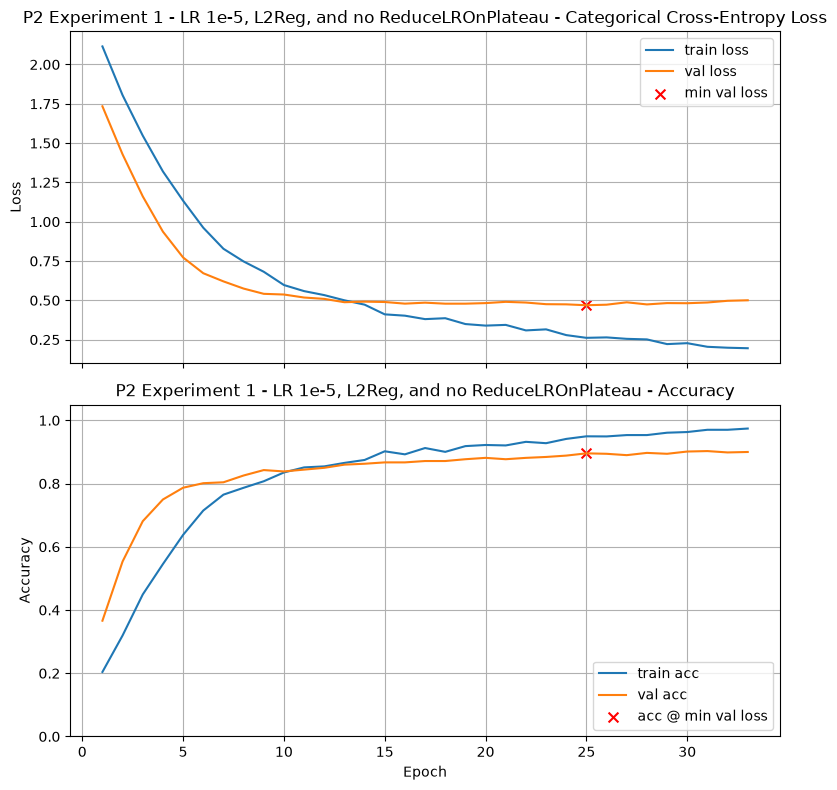

Final Training Loss:            0.1955
Final Training Accuracy:        0.9740
Final Validation Loss:          0.5004
Final Validation Accuracy:      0.8999
Minimum Validation Loss:        0.4688 (Epoch 25)
Validation Accuracy @ Min Loss: 0.8956

Test Loss: 0.4171
Test Accuracy: 0.9118

Validation-Test Gap (accuracy): 0.016200

Execution Time: 00:02:10


In [47]:
base_model = make_base_model_pooled(trainable=True)

model_p2_d2_l2_disable_reducelr = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p2_d2_l2_disable_reducelr, title="P2 Experiment 1 - LR 1e-5, L2Reg, and no ReduceLROnPlateau", lr_schedule=1e-5)

### Graded Questions

The reflection question is worth 5 points, and the validation accuracy question is worth 15 points. 

**Reflection Question:**

Which fully unfrozen configuration worked best for you, and what does that suggest about the role of head design and training hyperparameters when the MobileNetV2 backbone is trainable?

**Instructions:**

* Write a single paragraph (3–5 sentences).
* Explain your reasoning in choosing your three experimental designs.
* Identify the experiment that performed best.
* Briefly compare it with the other experiments, referring to both architectural choices (e.g., dense layers, dropout) and training hyperparameters (e.g., learning rate, `ReduceLROnPlateau`).
* Explain which differences you think were most important, based on the training and validation behavior you observed.
* Conclude with what your experiments suggest about training a model when the pretrained backbone is fully unfrozen.



Across my experiments I individually varied the learning rate, the regularization, and the ReduceLROnPlateau hyperparamters. In the first experiment, I saw that the default learning rate of 1e-4 collapsed the model performance to 0.5751 validation accuracy; by decreasing it to 1e-5 the performance increased to 0.8956, making the largest impact on model stability. Next, adding regularization to the model yielded a slightly performance boost to 0.8970. Finally, removing the ReduceLROnPlateau decreased performance slightly to 0.8956. 

With these results, we can see learning rate is the most important hyperparamater to maintain model performance in terms of validation accuracy. Secondly, l2 regularization was able to provide a moderate lift in performance by constraining the model. In terms of previous experiments, we were able to maintain similar performance to using the frozen models across different architectures, but did not see additional benefit in unfreezing the base. Through these experiments I found is important to slowly train the model when the base is unfrozen to avoid the model from collapsing, especially in terms of learning rate.

**Validation accuracy here (15 pts):**

In [48]:
# Set a2 to the validation accuracy found by your best model for this problem. 

a2 = 0.8970             # Replace 0.0 with your answer

In [49]:
# Graded Answer
# DO NOT change this cell in any way and do not make any other assignments to variable a1a in this problem       

print(f'a2 = {a2:.4f}') 

a2 = 0.8970


## Problem Three — Unfreezing Layers

**Goal.** Keep most of the pretrained MobileNetV2 backbone frozen and **unfreeze only the last \(N\) layers** for fine-tuning.

(In Problem 4, you will instead explore unfreezing the top **\(K\) MobileNetV2 blocks**.)

**Setup.** The backbone is MobileNetV2 with `include_top=False` and `pooling="avg"`, so it outputs a 1280-D feature vector. Do **not** add another pooling layer in the head.

After creating the backbone, unfreeze the last \(N\) layers using the following approach:

```python
N = 20

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False
```

### To Do

1. **Design at least three experiments** in which only the last \(N\) backbone layers are unfrozen. Vary one or more of the following:

   * \(N \in \{20, 40, 80\}\)
   * **Head architecture** (select one from Problem 1)
   * **Learning rate**
   * **EarlyStopping** parameters
   * **Regularization:** Dropout and/or L2
   * **ReduceLROnPlateau:** on vs. off

2. **Run and compare** the three experiments using a reduced value of `DATA_FRACTION`, focusing on:

   * how performance changes as more layers are unfrozen,
   * training stability and convergence,
   * and validation performance trends.

   Use these runs to **understand the effect of partial unfreezing**, not to identify a single globally optimal configuration.

3. **Select one configuration** (choice of \(N\) and training strategy), set `DATA_FRACTION = 1.0`, and rerun the notebook on the full dataset. Use this run when answering the graded questions.

### Notes

* As more layers are unfrozen, the model typically becomes **more sensitive to the learning rate**.
* Learning rates around \(1\times10^{-5}\) to \(3\times10^{-5}\) are reasonable starting points for partial fine-tuning.
* Small shifts in relative performance between reduced-data experiments and the full dataset are expected.
* Construct a **new backbone/model for each experiment** so that experiments do not inherit weights from previous runs.



#### Experiment 1: Varying N

##### N=20

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 1 - LR 1e-5 with L2Reg and N=20

Epoch 1/500


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 17s 105ms/step - accuracy: 0.2227 - loss: 2.1422 - val_accuracy: 0.5165 - val_loss: 1.5098 - learning_rate: 1.0000e-05
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.3612 - loss: 1.6964 - val_accuracy: 0.6753 - val_loss: 1.1842 - learning_rate: 1.0000e-05
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5137 - loss: 1.4090 - val_accuracy: 0.7253 - val_loss: 0.9725 - learning_rate: 1.0000e-05
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6081 - loss: 1.1890 - val_accuracy: 0.7539 - val_loss: 0.8265 - learning_rate: 1.0000e-05
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6833 - loss: 1.0393 - val_accuracy: 0.7954 - val_loss: 0.7143 - learning_rate: 1.0000e-05
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7250 - loss: 0.9077 - val_accuracy: 0.7940 - val_loss: 0.6478 - learning_rate: 1.0000e-05
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7652 - l

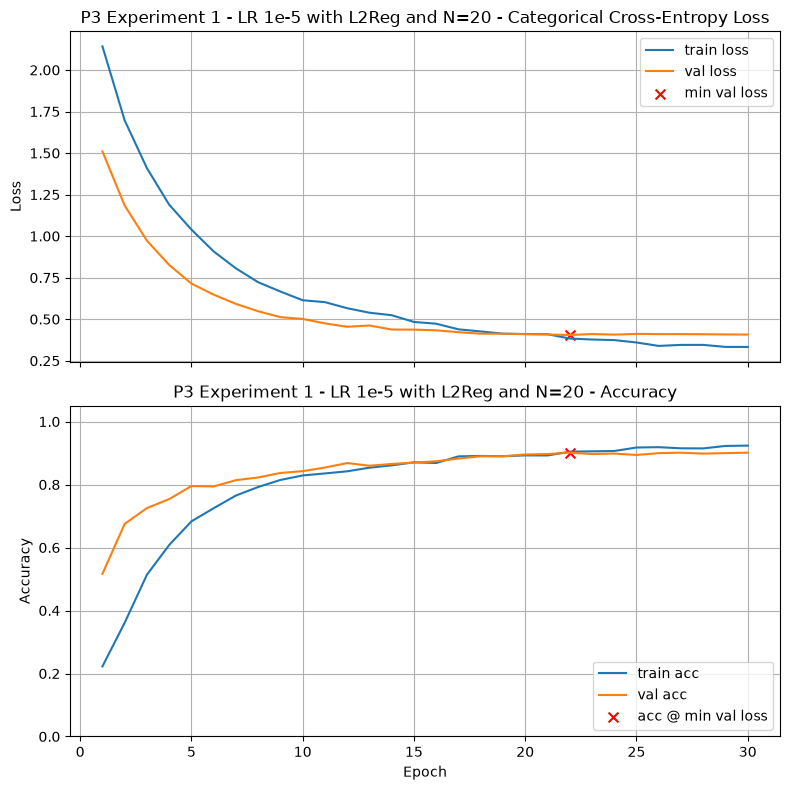

Final Training Loss:            0.3329
Final Training Accuracy:        0.9238
Final Validation Loss:          0.4075
Final Validation Accuracy:      0.9013
Minimum Validation Loss:        0.4049 (Epoch 22)
Validation Accuracy @ Min Loss: 0.9013

Test Loss: 0.3956
Test Accuracy: 0.8997

Validation-Test Gap (accuracy): 0.001555

Execution Time: 00:00:51


In [50]:
N = 20

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

model_p3_d1_baseline = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p3_d1_baseline, title="P3 Experiment 1 - LR 1e-5 with L2Reg and N=20", callbacks=[reduce_lr], lr_schedule=1e-5)

##### N=40

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 1 - LR 1e-5 with L2Reg and N=40

Epoch 1/500


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - accuracy: 0.1991 - loss: 2.1734 - val_accuracy: 0.4235 - val_loss: 1.6130 - learning_rate: 1.0000e-05
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.3288 - loss: 1.7611 - val_accuracy: 0.6381 - val_loss: 1.2100 - learning_rate: 1.0000e-05
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.4788 - loss: 1.4609 - val_accuracy: 0.7425 - val_loss: 0.9532 - learning_rate: 1.0000e-05
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5729 - loss: 1.2490 - val_accuracy: 0.7825 - val_loss: 0.7881 - learning_rate: 1.0000e-05
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6566 - loss: 1.0605 - val_accuracy: 0.8169 - val_loss: 0.6769 - learning_rate: 1.0000e-05
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7175 - loss: 0.9208 - val_accuracy: 0.8369 - val_loss: 0.5965 - learning_rate: 1.0000e-05
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7357 - l

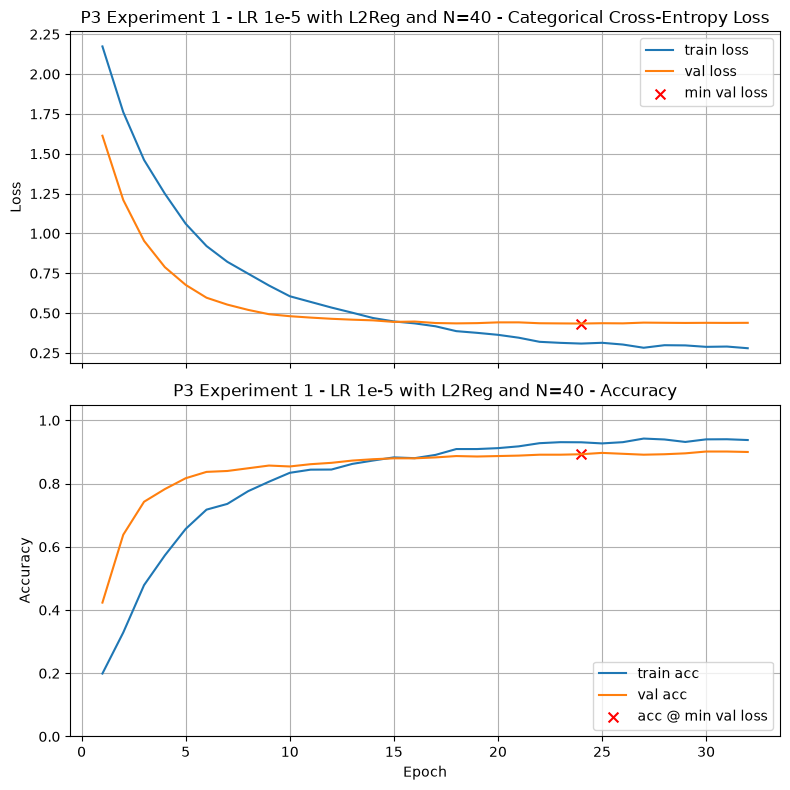

Final Training Loss:            0.2795
Final Training Accuracy:        0.9377
Final Validation Loss:          0.4389
Final Validation Accuracy:      0.8999
Minimum Validation Loss:        0.4344 (Epoch 24)
Validation Accuracy @ Min Loss: 0.8927

Test Loss: 0.3958
Test Accuracy: 0.9051

Validation-Test Gap (accuracy): 0.012376

Execution Time: 00:00:59


In [51]:
N = 40

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

model_p3_d1_n40 = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p3_d1_n40, title="P3 Experiment 1 - LR 1e-5 with L2Reg and N=40", callbacks=[reduce_lr], lr_schedule=1e-5)

##### N=80

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 1 - LR 1e-5 with L2Reg and N=40

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 125ms/step - accuracy: 0.2109 - loss: 2.1189 - val_accuracy: 0.3705 - val_loss: 1.6225 - learning_rate: 1.0000e-05
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.3506 - loss: 1.7422 - val_accuracy: 0.6209 - val_loss: 1.2880 - learning_rate: 1.0000e-05
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.4770 - loss: 1.4819 - val_accuracy: 0.7296 - val_loss: 1.0324 - learning_rate: 1.0000e-05
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.5818 - loss: 1.2503 - val_accuracy: 0.7825 - val_loss: 0.8340 - learning_rate: 1.0000e-05
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6541 - loss: 1.0712 - val_accuracy: 0.8183 - val_loss: 0.7050 - learning_rate: 1.0000e-05
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.7164 - loss: 0.9245 - val_accuracy: 0.8269 - val_loss: 0.6239 - learning_rate: 1.0000e-05
Epoch 7/500
88

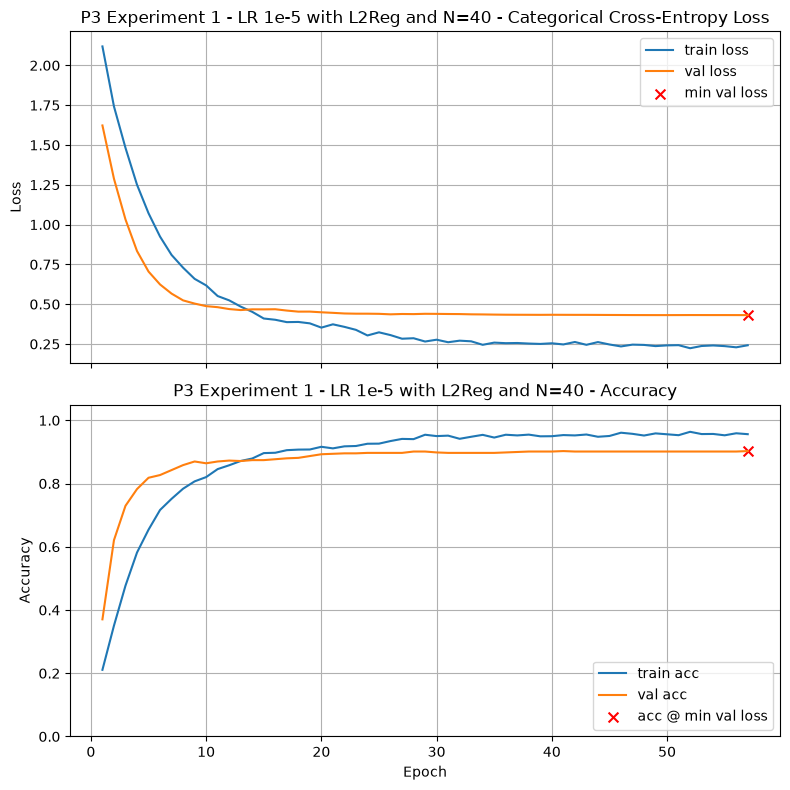

Final Training Loss:            0.2421
Final Training Accuracy:        0.9562
Final Validation Loss:          0.4314
Final Validation Accuracy:      0.9027
Minimum Validation Loss:        0.4314 (Epoch 57)
Validation Accuracy @ Min Loss: 0.9027

Test Loss: 0.3797
Test Accuracy: 0.9078

Validation-Test Gap (accuracy): 0.005036

Execution Time: 00:01:50


In [ ]:
N = 80

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

model_p3_d1_n80 = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p3_d1_n80, title="P3 Experiment 1 - LR 1e-5 with L2Reg and N=80", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 2: Varying Regularization

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization

Epoch 1/500


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 25s 138ms/step - accuracy: 0.2216 - loss: 2.0075 - val_accuracy: 0.4664 - val_loss: 1.4517 - learning_rate: 1.0000e-05
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.3491 - loss: 1.6225 - val_accuracy: 0.6695 - val_loss: 1.1152 - learning_rate: 1.0000e-05
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.4681 - loss: 1.3436 - val_accuracy: 0.7268 - val_loss: 0.8715 - learning_rate: 1.0000e-05
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5800 - loss: 1.1135 - val_accuracy: 0.7568 - val_loss: 0.7056 - learning_rate: 1.0000e-05
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6559 - loss: 0.9350 - val_accuracy: 0.7783 - val_loss: 0.5979 - learning_rate: 1.0000e-05
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7061 - loss: 0.8005 - val_accuracy: 0.7911 - val_loss: 0.5277 - learning_rate: 1.0000e-05
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7421 - l

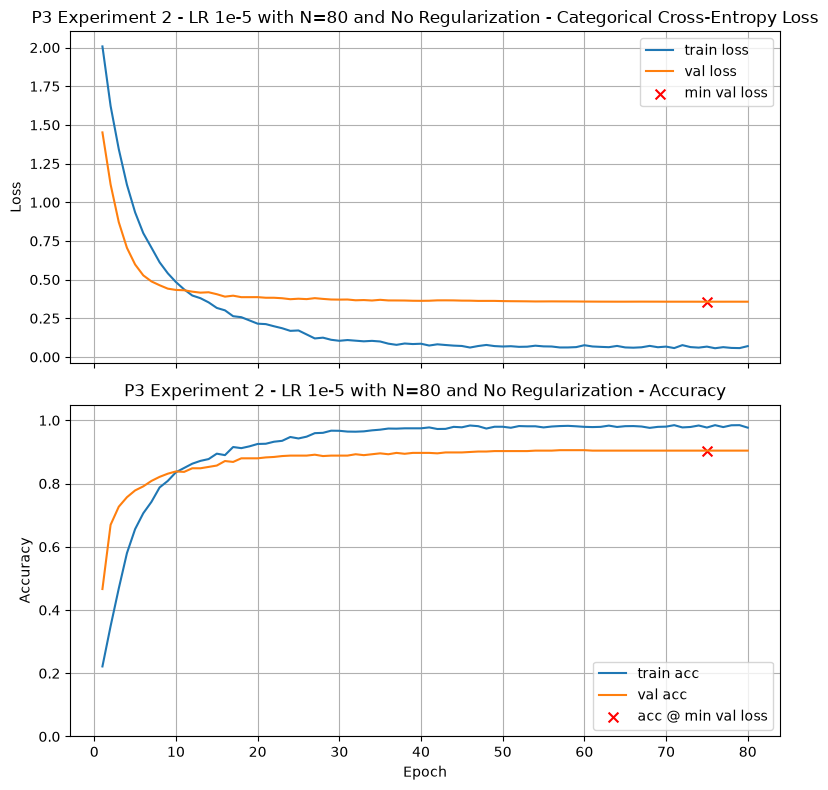

Final Training Loss:            0.0702
Final Training Accuracy:        0.9768
Final Validation Loss:          0.3574
Final Validation Accuracy:      0.9041
Minimum Validation Loss:        0.3573 (Epoch 75)
Validation Accuracy @ Min Loss: 0.9041

Test Loss: 0.2834
Test Accuracy: 0.9091

Validation-Test Gap (accuracy): 0.004942

Execution Time: 00:02:21


In [53]:
N = 80

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

model_p3_d2_no_reg = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p3_d2_no_reg, title="P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 3: Vary LR

##### 5e-4

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 2 - LR 5e-4 with N=80 and No Regularization

Epoch 1/500


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 124ms/step - accuracy: 0.7656 - loss: 0.6637 - val_accuracy: 0.7425 - val_loss: 2.4518 - learning_rate: 5.0000e-04
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9070 - loss: 0.2967 - val_accuracy: 0.7525 - val_loss: 2.3309 - learning_rate: 5.0000e-04
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9312 - loss: 0.2308 - val_accuracy: 0.8469 - val_loss: 1.0735 - learning_rate: 5.0000e-04
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9344 - loss: 0.2167 - val_accuracy: 0.8155 - val_loss: 1.8899 - learning_rate: 5.0000e-04
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9533 - loss: 0.1644 - val_accuracy: 0.7611 - val_loss: 2.2455 - learning_rate: 5.0000e-04
Epoch 6/500
85/88 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9577 - loss: 0.1425
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9576 - loss: 0

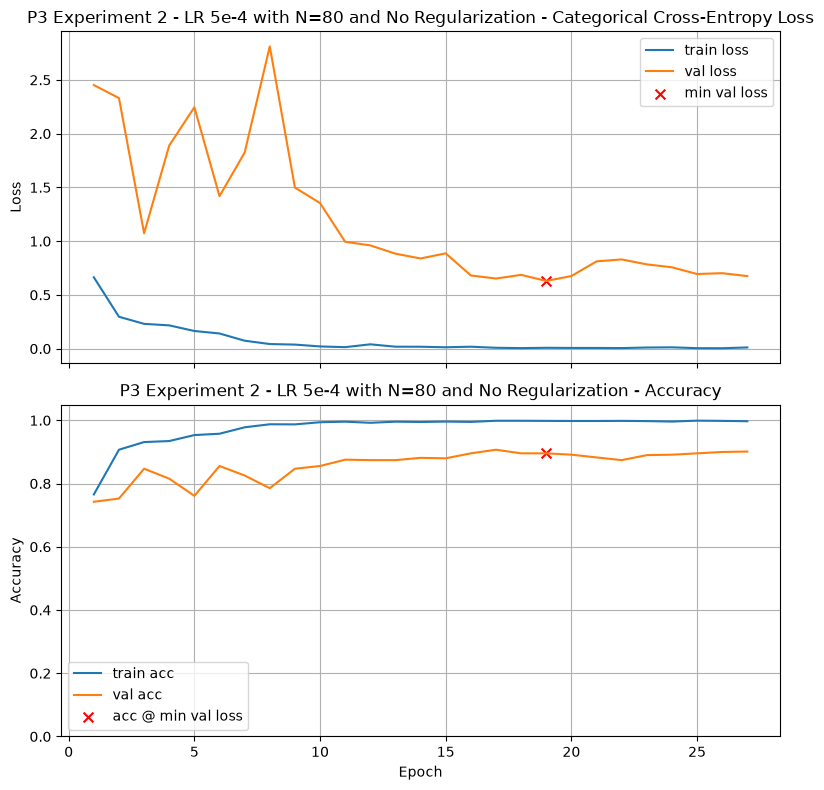

Final Training Loss:            0.0113
Final Training Accuracy:        0.9972
Final Validation Loss:          0.6750
Final Validation Accuracy:      0.9013
Minimum Validation Loss:        0.6300 (Epoch 19)
Validation Accuracy @ Min Loss: 0.8956

Test Loss: 0.5475
Test Accuracy: 0.9011

Validation-Test Gap (accuracy): 0.005504

Execution Time: 00:01:02


In [54]:
N = 80

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

model_p3_d3_lr_5e4 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p3_d3_lr_5e4, title="P3 Experiment 2 - LR 5e-4 with N=80 and No Regularization", callbacks=[reduce_lr], lr_schedule=5e-4)

### Graded Questions

The reflection question is worth 5 points, and the validation accuracy question is worth 15 points. 

**Reflection Question:**

Which partial-unfreezing configuration worked best for you, and what does that suggest about the effect of unfreezing the last \(N\) layers of MobileNetV2?

**Instructions:**

* Write a single paragraph (3–5 sentences).
* Explain your reasoning in choosing your three experimental designs.
* Identify the experiment that performed best.
* Briefly compare it with the other experiments, referring to both architectural choices (especially the **number \(N\) of unfrozen layers**, as well as dense layers or dropout) and training hyperparameters (e.g., learning rate, `ReduceLROnPlateau`).
* Explain which differences you think were most important, based on the training and validation behavior you observed.
* Conclude with what your experiments suggest about how much of a pretrained backbone should be unfrozen during fine-tuning.



I implemented three experiments, varying the number of layers to unfreeze, with/without l2 regularization, and the learning rate. I found that varying the number of layers to unfreeze was the most important to the model performance. This provided a best validation accuracy at the minimal loss of 0.9027 at N=80, a lift ~0.01 over the previous model which was entirely unfroze. Next, I built on this optimal N by attempting to remove l2 regularization which further boosted performance to 0.9041. Finally, I attempted to vary the learning rate to 5e-4, but this collapsed the model performance. Therefore, the model with no l2 regularization and N=80 was the best performer.

Based on these results, I found it is important to retain a low learning rate when unfreezing a high amount of layers of the network (such as N=80). Additionally, I discovered that L2 regularization did not have a strong impact on the model, since the delta was ~0.0014 and could be noise. I can conclude that unfreezing N layers rather than the whole network did allow for stronger model performance, but learning rate is still critical to be mindful of. Learning rate could likely be increased if only unfreezing a small number of layers.

**Validation accuracy here (15 pts):**

In [55]:
# Set a3 to the validation accuracy found by your best model for this problem. 

a3 = 0.9041             # Replace 0.0 with your answer

In [56]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a3 = {a3:.4f}') 

a3 = 0.9041


## Problem Four — Unfreezing Convolution Blocks

**Goal.** Fine-tune MobileNetV2 by unfreezing the **last $K$ convolutional stages/blocks** rather than the last $N$ individual layers, as in Problem 3. This provides a more meaningful way to control how much of the pretrained backbone is allowed to adapt.

**Setup.** The backbone is MobileNetV2 with `include_top=False` and `pooling="avg"`, so it outputs a **1280-D feature vector**. Do **not** add another pooling layer in the head.

After creating the backbone, unfreeze the top $K$ stages using the following approach:

```python
block_prefixes = [
    "block_1", "block_2", "block_3", "block_4",
    "block_5", "block_6", "block_7", "block_8",
    "block_9", "block_10", "block_11", "block_12",
    "block_13", "block_14", "block_15", "block_16",
    "Conv_1",   # final 1×1 convolution stage before pooling
]

K = 3

base_model = make_base_model_pooled(trainable=False)

# Allow selected layers to be made trainable
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        # Often recommended to keep BN frozen during fine-tuning
        layer.trainable = False
    else:
        layer.trainable = any(
            layer.name.startswith(prefix)
            for prefix in block_prefixes[-K:]
        )
```

For example:

* $K=1$ unfreezes only `Conv_1`.
* $K=2$ unfreezes `block_16` and `Conv_1`.
* $K=3$ unfreezes `block_15`, `block_16`, and `Conv_1`.

### To Do

1. **Design at least three experiments** in which the **last $K$ stages are unfrozen**. Vary one or more of the following:

   * $K \in {1, 2, 3, 5}$
     *(Here, $K$ counts stages/blocks, not individual Keras layers.)*
   * **BatchNormalization strategy:** keep BN frozen vs. allow BN layers in the selected blocks to be trainable.
   * **Head architecture** (select one from Problem 1).
   * **Learning rate**
   * **EarlyStopping** parameters
   * **Regularization:** Dropout and/or L2
   * **ReduceLROnPlateau:** on vs. off

2. **Run and compare** the experiments using a reduced value of `DATA_FRACTION`, focusing on:

   * how performance changes as more blocks are unfrozen,
   * whether making BatchNormalization layers trainable helps or destabilizes training,
   * training stability and convergence,
   * and validation performance trends.

   Use these runs to **understand the effect of block-level fine-tuning** and to narrow down reasonable configurations, rather than to identify a single globally optimal setting.

3. **Select one configuration** (choice of $K$, BatchNormalization strategy, and training strategy), set:

```python
DATA_FRACTION = 1.0
```

and rerun the notebook on the full dataset. Use this run when answering the graded questions.

### Notes

* Your backbone was built with `pooling="avg"`, so **do not** add another `GlobalAveragePooling2D()` layer.
* Unfreezing more blocks generally makes training **more sensitive to the learning rate** and may increase instability; this is part of what you are investigating.
* Learning rates around $1\times10^{-5}$ to $3\times10^{-5}$ are reasonable starting points for block-level fine-tuning.
* Small shifts in relative performance between reduced-data experiments and the full dataset are expected.
* Construct a **new backbone/model for each experiment** so that experiments do not inherit weights from previous runs.



#### Experiment 1: K=1

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=1

Epoch 1/500


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 13s 90ms/step - accuracy: 0.2583 - loss: 1.9790 - val_accuracy: 0.6180 - val_loss: 1.2389 - learning_rate: 1.0000e-05
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.4400 - loss: 1.4352 - val_accuracy: 0.7511 - val_loss: 0.8930 - learning_rate: 1.0000e-05
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5796 - loss: 1.1348 - val_accuracy: 0.8140 - val_loss: 0.6992 - learning_rate: 1.0000e-05
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6473 - loss: 0.9344 - val_accuracy: 0.8412 - val_loss: 0.5811 - learning_rate: 1.0000e-05
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6979 - loss: 0.8207 - val_accuracy: 0.8469 - val_loss: 0.5014 - learning_rate: 1.0000e-05
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7389 - loss: 0.7174 - val_accuracy: 0.8584 - val_loss: 0.4504 - learning_rate: 1.0000e-05
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7553 - lo

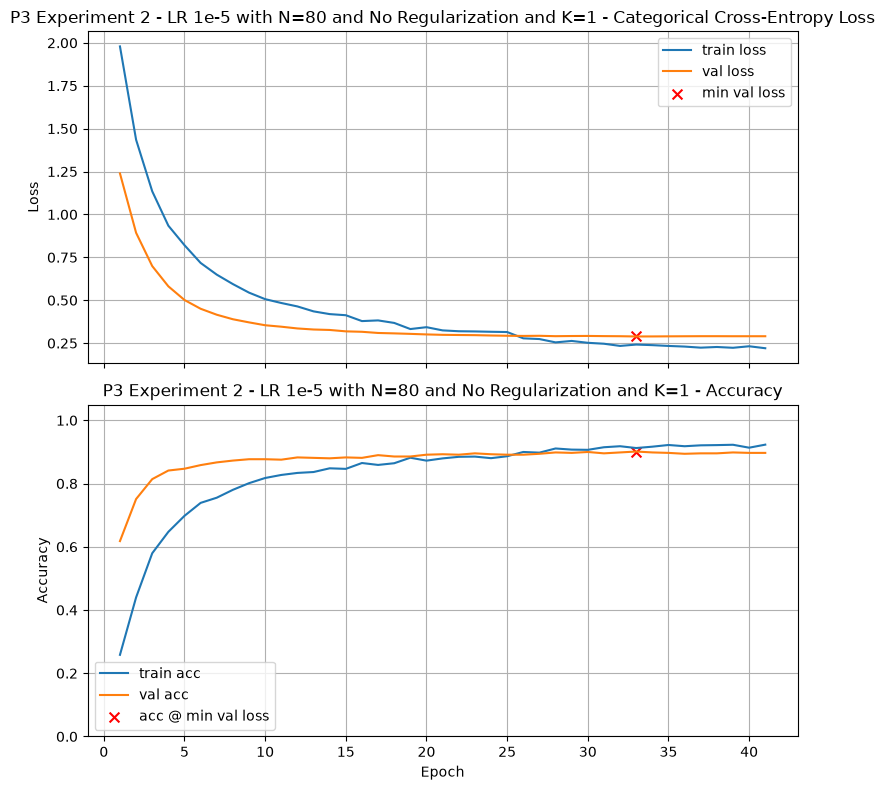

Final Training Loss:            0.2204
Final Training Accuracy:        0.9230
Final Validation Loss:          0.2904
Final Validation Accuracy:      0.8970
Minimum Validation Loss:        0.2889 (Epoch 33)
Validation Accuracy @ Min Loss: 0.9013

Test Loss: 0.2617
Test Accuracy: 0.8957

Validation-Test Gap (accuracy): 0.005566

Execution Time: 00:00:55


In [ ]:
block_prefixes = [
    "block_1", "block_2", "block_3", "block_4",
    "block_5", "block_6", "block_7", "block_8",
    "block_9", "block_10", "block_11", "block_12",
    "block_13", "block_14", "block_15", "block_16",
    "Conv_1",   # final 1×1 convolution stage before pooling
]

K = 1

base_model = make_base_model_pooled(trainable=False)

# Allow selected layers to be made trainable
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        # Often recommended to keep BN frozen during fine-tuning
        layer.trainable = False
    else:
        layer.trainable = any(
            layer.name.startswith(prefix)
            for prefix in block_prefixes[-K:]
        )

model_p4_d1_k1 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p4_d1_k1, title="P4 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=1", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 2: K=3

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=3

Epoch 1/500


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


88/88 ━━━━━━━━━━━━━━━━━━━━ 13s 91ms/step - accuracy: 0.3000 - loss: 1.8062 - val_accuracy: 0.7082 - val_loss: 1.1223 - learning_rate: 1.0000e-05
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5675 - loss: 1.1196 - val_accuracy: 0.8140 - val_loss: 0.6463 - learning_rate: 1.0000e-05
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7011 - loss: 0.8119 - val_accuracy: 0.8455 - val_loss: 0.4667 - learning_rate: 1.0000e-05
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7631 - loss: 0.6327 - val_accuracy: 0.8670 - val_loss: 0.3813 - learning_rate: 1.0000e-05
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7991 - loss: 0.5339 - val_accuracy: 0.8841 - val_loss: 0.3451 - learning_rate: 1.0000e-05
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8244 - loss: 0.4872 - val_accuracy: 0.8827 - val_loss: 0.3313 - learning_rate: 1.0000e-05
Epoch 7/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8504 - lo

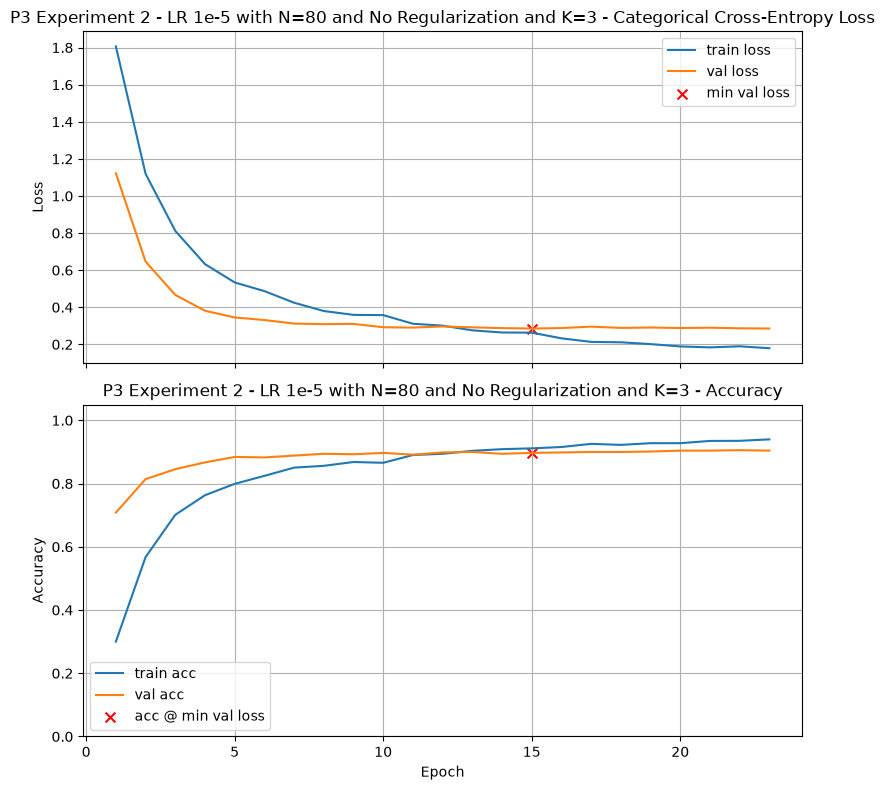

Final Training Loss:            0.1793
Final Training Accuracy:        0.9398
Final Validation Loss:          0.2856
Final Validation Accuracy:      0.9041
Minimum Validation Loss:        0.2853 (Epoch 15)
Validation Accuracy @ Min Loss: 0.8970

Test Loss: 0.2570
Test Accuracy: 0.9064

Validation-Test Gap (accuracy): 0.009421

Execution Time: 00:00:38


In [ ]:
block_prefixes = [
    "block_1", "block_2", "block_3", "block_4",
    "block_5", "block_6", "block_7", "block_8",
    "block_9", "block_10", "block_11", "block_12",
    "block_13", "block_14", "block_15", "block_16",
    "Conv_1",   # final 1×1 convolution stage before pooling
]

K = 3

base_model = make_base_model_pooled(trainable=False)

# Allow selected layers to be made trainable
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        # Often recommended to keep BN frozen during fine-tuning
        layer.trainable = False
    else:
        layer.trainable = any(
            layer.name.startswith(prefix)
            for prefix in block_prefixes[-K:]
        )

model_p4_d1_k3 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p4_d1_k3, title="P4 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=3", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 3: K=5

/tmp/ipykernel_47174/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=5

Epoch 1/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 90ms/step - accuracy: 0.3046 - loss: 1.8190 - val_accuracy: 0.7411 - val_loss: 1.1614 - learning_rate: 1.0000e-05
Epoch 2/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6238 - loss: 1.0495 - val_accuracy: 0.8412 - val_loss: 0.5313 - learning_rate: 1.0000e-05
Epoch 3/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7560 - loss: 0.6613 - val_accuracy: 0.8598 - val_loss: 0.3870 - learning_rate: 1.0000e-05
Epoch 4/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8016 - loss: 0.5383 - val_accuracy: 0.8798 - val_loss: 0.3407 - learning_rate: 1.0000e-05
Epoch 5/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8425 - loss: 0.4523 - val_accuracy: 0.8884 - val_loss: 0.3063 - learning_rate: 1.0000e-05
Epoch 6/500
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8589 - loss: 0.4139 - val_accuracy: 0.8856 - val_loss: 0.2831 - learning_rate: 1.0000

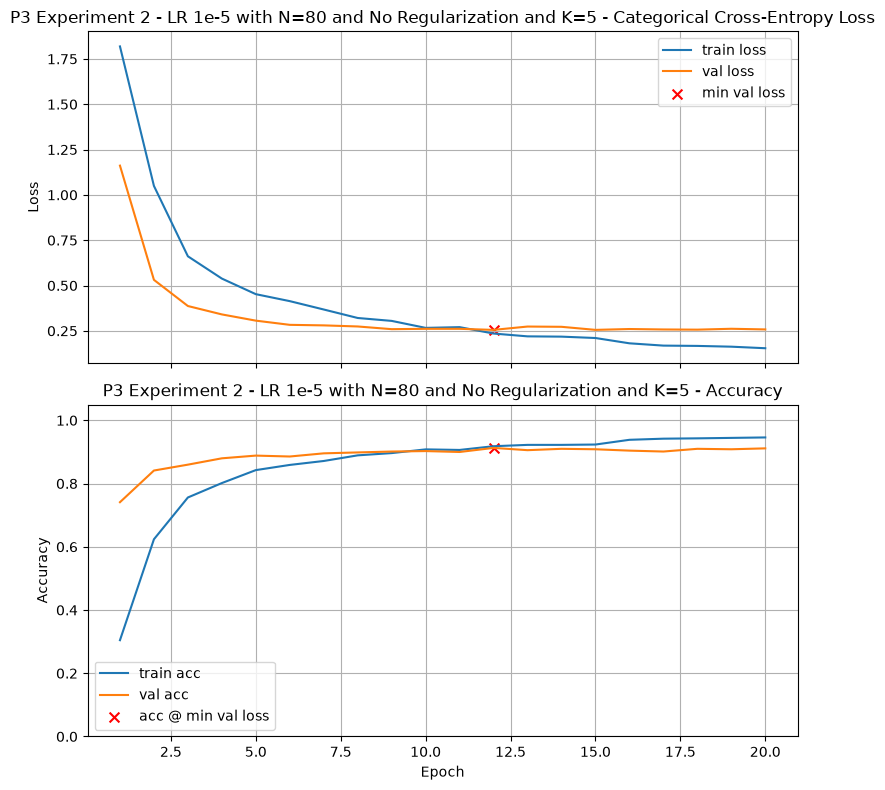

Final Training Loss:            0.1541
Final Training Accuracy:        0.9458
Final Validation Loss:          0.2579
Final Validation Accuracy:      0.9113
Minimum Validation Loss:        0.2553 (Epoch 12)
Validation Accuracy @ Min Loss: 0.9127

Test Loss: 0.2592
Test Accuracy: 0.9118

Validation-Test Gap (accuracy): 0.000968

Execution Time: 00:00:37


In [ ]:
block_prefixes = [
    "block_1", "block_2", "block_3", "block_4",
    "block_5", "block_6", "block_7", "block_8",
    "block_9", "block_10", "block_11", "block_12",
    "block_13", "block_14", "block_15", "block_16",
    "Conv_1",   # final 1×1 convolution stage before pooling
]

K = 5

base_model = make_base_model_pooled(trainable=False)

# Allow selected layers to be made trainable
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        # Often recommended to keep BN frozen during fine-tuning
        layer.trainable = False
    else:
        layer.trainable = any(
            layer.name.startswith(prefix)
            for prefix in block_prefixes[-K:]
        )

model_p4_d1_k5 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p4_d1_k5, title="P4 Experiment 3 - LR 1e-5 with N=80 and No Regularization and K=5", callbacks=[reduce_lr], lr_schedule=1e-5)

### Graded Questions

The reflection question is worth 5 points, and the validation accuracy question is worth 15 points. 

**Reflection Question:**

Which block-unfreezing configuration worked best for you, and what does that suggest about the effect of unfreezing the last \(K\) MobileNetV2 blocks?

**Instructions:**

* Write a single paragraph (3–5 sentences).
* Explain your reasoning in choosing your three experimental designs.
* Identify the experiment that performed best.
* Briefly compare it with the other experiments, referring to both architectural choices (especially the **number \(K\) of unfrozen blocks**, as well as dense layers or dropout) and training hyperparameters (e.g., learning rate, `ReduceLROnPlateau`).
* If you experimented with BatchNormalization, comment briefly on whether keeping BN frozen or allowing it to train appeared to help or destabilize training.
* Explain which differences you think were most important, based on the training and validation behavior you observed.
* Conclude with what your experiments suggest about selecting how many pretrained blocks to unfreeze during fine-tuning.



After attempting three experiments, varying K=1, K=3 and K=5, I found that K=5 was the best performing model. This model achieved 0.9127 validation accuracy in 12 epochs in comparison to 0.0.8970 at K=3 and 0.9013 at K=1. This shows that increasing the number of MobileNetV2 blocks improved the generalization on our specific domain of images. The layers were able to learn the class specific patterns better and the early layers were able to retain their ability to extract features. Varying K provided the strongest performance across all experiments in this project, showing on this specific dataset the targetted convolutional layer unfreezing performed better than unfreezing the entire model or a specific number of layers.

**Validation accuracy (15pts):**

In [62]:
# Set a4 to the validation accuracy found by your best model for this problem. 

a4 = 0.9127             # Replace 0.0 with your answer

In [63]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a4 = {a4:.4f}') 

a4 = 0.9127


## Problem 5: Final Reflection

Run the next cell and consider all your experiments in this homework. 

This reflection question is worth 5 points. 

In [64]:
# Print out summary of validation accuracy for each experiment

print_results()

P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=5	0.9127	12
P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization	0.9041	75
P3 Experiment 1 - LR 1e-5 with L2Reg and N=40	0.9027	57
P3 Experiment 1 - LR 1e-5 with L2Reg and N=20	0.9013	22
P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=1	0.9013	33
P1 Design 1. Dense 256 with lr 1e-4     	0.8970	10
P1 Design 1. Dense 256 with ReduceLROnPlateau	0.8970	1
P1 Design 2. Dense-Dropout-Dense-Dropout lr 1e-4	0.8970	9
P2 Experiment 1 - LR 1e-5 with L2Reg    	0.8970	23
P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=3	0.8970	15
P2 Experiment 1 - LR 1e-5               	0.8956	1
P2 Experiment 1 - LR 1e-5, L2Reg, and no ReduceLROnPlateau	0.8956	25
P3 Experiment 2 - LR 5e-4 with N=80 and No Regularization	0.8956	19
P1 Design 1. Dense 256 with Dropout and ReduceLROnPlateau	0.8941	4
P1 Design 2. Dense-Dropout-Dense-Dropout ReuceLROnPlateau	0.8941	4
P1 Design 1. Dense 256 with Dropout     	0.8870	2
P1 Des

### Graded Question

### Final Reflection

Looking across the validation accuracies from your **full-dataset runs**, what patterns or lessons stand out from the different transfer-learning strategies you explored?

**Instructions:**

* Write a single paragraph (3–5 sentences).
* Compare the overall results from the frozen backbone, fully trainable backbone, partial layer unfreezing, and block-level unfreezing experiments.
* Highlight at least one design choice or training hyperparameter that appeared especially important.
* Mention any result that surprised you or differed from what you expected, if applicable.
* Conclude with a brief takeaway about what you learned about transfer learning from the homework.



**Your paragraph here (5pts):**

> Replace this sentence with your answer. 

## Appendix: What is MobileNetV2 (in plain English)?

`MobileNetV2` is a lightweight convolutional neural network (CNN) designed for efficient inference on resource-constrained devices while maintaining strong image-classification accuracy.

It achieves this with two important ideas:

1. **Depthwise-separable convolutions**

   Instead of using one expensive 3×3 convolution that mixes spatial information and channels at the same time, MobileNetV2 separates the operation into two steps:

   * a **depthwise 3×3 convolution**, which applies one spatial filter to each input channel separately, followed by
   * a **pointwise 1×1 convolution**, which mixes information across channels.

   This greatly reduces the number of parameters and computations compared with a standard convolution. ([arXiv][1])

2. **Inverted residual blocks with a linear bottleneck**

   A typical MobileNetV2 block has the following structure:

   * **Expand (1×1 convolution):** increase the number of channels, often by a factor of about 6, and apply a nonlinear activation.
   * **Depthwise (3×3 convolution):** process each channel separately and apply a nonlinear activation.
   * **Project (1×1 convolution):** reduce the number of channels again, but **without** applying a nonlinear activation. This is the **linear bottleneck**.

   If the input and output shapes match and the stride is 1, the block also adds a **skip connection**.

   The term **inverted residual** refers to the fact that the representation becomes wide inside the block and narrow again at the output, rather than the other way around.

   The final linear projection helps preserve information when the representation is compressed back to a lower-dimensional space. ([arXiv][1])

---

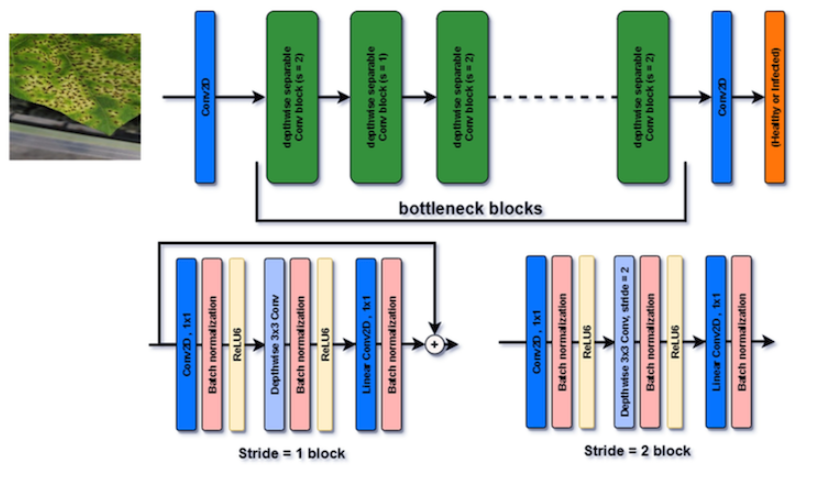

---

### What was MobileNetV2 trained on?

The Keras ImageNet weights for MobileNetV2 were trained on **ImageNet-1K**, a standard image-classification dataset containing:

* **1,281,167** training images
* **50,000** validation images
* **100,000** test images
* **1000 classes**

A common input size for MobileNetV2 is **224×224**. ([ImageNet][2])

For this homework, we use smaller **150×150** images to reduce training time.

Because we use:

```python
include_top=False
```

the pretrained convolutional backbone can operate on image sizes other than 224×224.

---

### Preprocessing

The preprocessing used for a pretrained network should match the preprocessing used when that network was originally trained.

For MobileNetV2, Keras provides:

```python
mobilenet_v2.preprocess_input
```

This function takes pixel values in their original approximately **0–255** range and scales them to approximately **[-1, 1]**.

In this homework, the image-loading pipeline applies this preprocessing before passing images to MobileNetV2. ([keras.io][3])

---

### How Keras exposes MobileNetV2

The following Keras call:

```python
tf.keras.applications.mobilenet_v2.MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg"
)
```

returns a pretrained MobileNetV2 backbone with the original ImageNet classification head removed.

With:

```python
pooling="avg"
```

Keras applies **Global Average Pooling** to the final convolutional feature map. The result is a **1280-dimensional feature vector** for each image.

To use this backbone as a **frozen feature extractor**, we additionally set:

```python
base_model.trainable = False
```

The classification head that we add afterward can then be trained while the pretrained MobileNetV2 weights remain unchanged.

---

### What happens if `pooling="avg"` is omitted?

Without pooling, the backbone produces a spatial feature map rather than a single feature vector.

For a 224×224 input image, this feature map is typically:

```text
7 × 7 × 1280
```

Before connecting this to Dense layers, we would normally reduce the spatial dimensions using:

```python
GlobalAveragePooling2D()
```

which produces a 1280-dimensional vector.

`GlobalMaxPooling2D()` is another possible choice.

Using:

```python
Flatten()
```

is usually less attractive here because it would convert:

```text
7 × 7 × 1280
```

into:

```text
62,720
```

features, creating a much larger classification head.

In this homework, however, we use:

```python
pooling="avg"
```

inside MobileNetV2 itself, so **do not add another `GlobalAveragePooling2D()` layer**.

---

### How we use MobileNetV2 in this homework

We will experiment with several ways of using the pretrained backbone:

* **Frozen feature extraction:** keep all MobileNetV2 layers frozen and train only a new classification head.
* **Fully trainable backbone:** allow all MobileNetV2 layers to be updated during training.
* **Partial unfreezing:** keep most of the backbone frozen while allowing only selected upper layers or blocks to be updated.

These experiments let us investigate how much of the pretrained representation should be preserved and how much should be adapted to the Intel Image Classification dataset.

---

### TL;DR Summary

* Think of a MobileNetV2 block as:

  **expand → depthwise convolution → project (+ optional skip connection)**

* MobileNetV2 was pretrained to distinguish **1000 ImageNet classes**.

* In this homework, we reuse those learned visual features and train the model for our **6 Intel image classes**.

* With:

  ```python
  include_top=False,
  pooling="avg"
  ```

  the backbone outputs a **1280-D feature vector**.

* To use the backbone as a frozen feature extractor, set:

  ```python
  base_model.trainable = False
  ```

* Always match preprocessing to the pretrained backbone. For MobileNetV2, use:

  ```python
  mobilenet_v2.preprocess_input
  ```

  which scales the original pixel values to approximately **[-1, 1]**. ([keras.io][3])

---

### See also

* [https://www.analyticsvidhya.com/blog/2023/12/what-is-mobilenetv2/](https://www.analyticsvidhya.com/blog/2023/12/what-is-mobilenetv2/)

[1]: https://arxiv.org/abs/1801.04381
[2]: https://www.image-net.org/
[3]: https://keras.io/api/applications/mobilenet/mobilenet_models/


